# 346. Linked HP word pairs at database scale, on pairs whose answer is known

**Result: KILL**, by the rule written before the search. Searching whole proteomes, no
HP score finds BCL-2 from CED-9 or CED-9 from BCL-2. Under the linked key BCL-2 ranks
9,952 of 19,732 human proteins, and 48% of dipeptide-shuffled decoys score as high. CED-9
ranks 4,493 of 19,792 *C. elegans* proteins, with a decoy rate of 21%. The linked key ranks
the true partner a little better than B3 in both directions (9,952 against 10,798; 4,493
against 5,244), so prediction P2 failed. But both decoy rates are far above the 0.01 KILL
line. BCL-2's best key over the two whole sequences lies wholly off the structure
alignment, so even its score is a chance match. Each human protein shares a median of
41,720 linked keys with CED-9 over all diagonals; notebook 294 counted 3,896 for two
131-residue proteins on one diagonal. Pairs 3 to 6 against Swiss-Prot (prediction P5) and
kmerseek's own chained search wait on two Sherlock jobs.

## The question, and the decision it informs

[Notebook 294](294_linked_hp_word_pairs_kill_test_pfam_seed.ipynb) (PR 143) asked whether a
search key made of two short exact words over the hydrophobic/polar (HP) alphabet finds
more remote Pfam homologs than one longer exact word. It scored each pair on that pair's
own alignment and found that the gain came from scoring a second extended segment, not
from the second exact word. Three things it could not test, because it never searched a
database: false positives against thousands of unrelated proteins, chance key matches off
the alignment's diagonal, and kmerseek's own chaining.

This notebook searches whole proteomes and Swiss-Prot with the same four scores, on six
pairs whose answer is known before the search. **The decision:** is a linked key worth
building into kmerseek's index for database search, beyond what scoring a second segment
(B3) already gives? A PASS would put the linked key on the kmerseek roadmap; a KILL closes
it for the HP alphabet.

**Data.** Queries and partners: human BCL-2 (UniProt P10415) and *C. elegans* CED-9
(P41958); *Borrelia burgdorferi* P66 (H7C7N8) and human CD47 (Q08722); four Pfam seed pairs
from notebook 294's report half at 20–30% identity. Databases: the human proteome notebook
241 searched (GENCODE v49 canonical translations, 19,732 proteins), the *C. elegans*
UniProt reference proteome UP000001940 (19,792 proteins), the *B. burgdorferi* B31
reference proteome UP000001807 (1,291 proteins) and Swiss-Prot (572,970 proteins). Every
count, file and date is in `tables/346_inputs.tsv` and `tables/346_databases.tsv`, written
by `scripts/make_346_inputs.py`. The scores are computed by `scripts/346_database_scan.py`
(Python, no kmerseek); kmerseek's own search runs on Sherlock
(`scripts/346_kmerseek_ced9_human.sbatch`).

### Words used in this notebook, each defined once

- **HP alphabet** (`hp_thomas_dill2`): every residue becomes H (hydrophobic: A, C, F, I, L,
  M, V, W, Y) or P (polar: the other 11). Two residues match when they fall in the same class.
- **Word**: a run of consecutive residues; an **exact shared word** is a run whose HP
  classes are identical in both proteins, residue by residue, with no gap.
- **Seed**: an exact shared word that starts a hit. **Extension**: growing the seed left
  and right along the same diagonal, +1 per matching position and −2 per mismatch, keeping
  the best total (notebook 232's rule). The result is a gap-free **segment**.
- **Strobemer** (the field's word, Sahlin 2021), called the **linked key** here: two exact
  6-letter HP words, called **anchors**, whose starts are at most 32 residues apart in both
  proteins. The **gap** is the number of residues between the two anchors; it is not part
  of the key, so the gap may differ between the two proteins. A key's score is the best
  total of one segment holding both anchors, or two segments, one through each anchor,
  that do not overlap in either protein. This is notebook 294's chosen setting.
- **B2**: one exact 8-letter HP word plus extension.
- **B3**: B2's 8-letter word plus the best second segment within 32 residues, before or
  after it (the second segment needs only one matching residue, no second exact word).
- **Randstrobe**: the linked key with one key per position: each protein, on its own,
  picks the second anchor for every first anchor by a hash rule (Sahlin 2021), so a key is
  shared only when both proteins pick the same partner word.
- **Decoy**: a database protein with its residues shuffled. Two shuffles, both with fixed
  seeds: (a) every residue moved at random (notebook 232's null), and (b) a shuffle that
  keeps the count of every pair of adjacent residues (dipeptide), which keeps runs of H and
  P residues. (b) is the headline.
- **Rank** of the true partner: 1 plus the number of other real database proteins scoring
  at or above it (ties count against the partner).
- **Decoy rate**: the share of decoy proteins scoring at or above the true partner. It
  plays the part of a **false-positive rate**: the share of unrelated proteins a cut-off at
  the partner's score would also call.
- **Key matches**: the number of keys two proteins share, over every diagonal.
- Notebook 241's code calls one kmerseek alphabet, k and metric an *arm*; this notebook
  writes "kmerseek setting".

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import bits_ceiling_utils as bu
import hp_conservation_utils as hc
import known_pair_search_utils as ku
import linked_pairs_utils as lp
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(60)

ROOT = Path("..")
FIG = ROOT / "figures"
TAB = ROOT / "tables"
DATA = Path("/Users/olga/data/linked-pairs")
V = dict(
    zip(
        *pl.read_csv(TAB / "346_inputs.tsv", separator="\t")
        .select("quantity", "value")
        .to_dict(as_series=False)
        .values()
    )
)
INPUTS = pl.read_csv(TAB / "346_inputs.tsv", separator="\t")
KNOWN = pl.read_csv(TAB / "346_known_pairs.tsv", separator="\t")
PFAM = pl.read_csv(TAB / "346_pfam_pairs.tsv", separator="\t")
DBS = pl.read_csv(TAB / "346_databases.tsv", separator="\t")
SEQ = ku.read_fasta(TAB / "346_sequences.fasta")
SCAN_FILE = {
    "human GENCODE v49 canonical": DATA / "346_scan_human_gencode_v49.parquet",
    "C. elegans UniProt UP000001940": DATA
    / "346_scan_celegans_uniprot_UP000001940.parquet",
    "B. burgdorferi B31 UniProt UP000001807": DATA
    / "346_scan_borrelia_uniprot_UP000001807.parquet",
    "Swiss-Prot": DATA / "346_scan_swissprot.parquet",
}
SCAN = {db: pl.read_parquet(f) for db, f in SCAN_FILE.items() if f.exists()}
TOOL = "no kmerseek; Python scorer (linked_pairs_utils.diagonal_scan), hp_thomas_dill2, mismatch -2"
print(
    "Inputs quoted from earlier notebooks (tables/346_inputs.tsv): quantity = value [kind; source; cell]"
)
for r in INPUTS.iter_rows(named=True):
    print(
        f"  {r['quantity']} = {r['value']:g} [{r['kind']}; {r['source']}; cell {r['cell'] or '-'}]"
    )
print("Databases:")
for r in DBS.iter_rows(named=True):
    print(
        f"  {r['database']}: {r['n_proteins']:,} proteins, {r['n_residues']:,} residues, file of {r['file_date']}"
    )
print("score tables present:", ", ".join(SCAN) or "none")

Inputs quoted from earlier notebooks (tables/346_inputs.tsv): quantity = value [kind; source; cell]
  kappa_hp_thomas_dill2_pfam_20_30 = 0.463 [measured; tables/245_inputs.tsv (nb 230 section 2, Pfam seed pairs at 20-30% identity); cell -]
  best_rank_BCL2 = 213 [measured; tables/245_inputs.tsv (nb 241 section 6, best rank over every alphabet, k and metric); cell -]
  n_targets_at_best_BCL2 = 18064 [measured; tables/245_inputs.tsv (nb 241 section 6, human proteins hit at the arm of the best rank); cell -]
  best_rank_CD47 = 166 [measured; tables/245_inputs.tsv (nb 241 section 6, best rank over every alphabet, k and metric); cell -]
  n_targets_at_best_CD47 = 18775 [measured; tables/245_inputs.tsv (nb 241 section 6, human proteins hit at the arm of the best rank); cell -]
  K_proteome = 0.018 [approximate; tables/245_inputs.tsv (kmerseek docs Part 1, DB table (one proteome)); cell -]
  n_residues_proteome = 1.1e+07 [approximate; tables/245_inputs.tsv (kmerseek docs Part 1, DB table (one

## 1. The pairs, residue by residue, before any search

Each block shows both sequences, an identity line (`|`), the HP class strings (h, p) with a
class-match line, a line marking every column inside an exact shared 6-letter HP word
(`=`), the longest class-identical run (`^`), the best linked key's two anchors (`L`) and
B3's seed segment (`S`) and second segment (`2`). The key and B3 marks are restricted to
the alignment shown.

### 1a. BCL-2 and CED-9 (pair 1)

The structure alignment is notebook 245's USalign alignment of the two AlphaFold models
(`tables/245_bcl2_ced9_usalign_pairs.tsv`), CED-9 as the query. Then the BH1 block, BCL-2
130–166 against CED-9 154–190, on its own: one gap-free diagonal.

In [2]:
pairs245 = pl.read_csv(TAB / "245_bcl2_ced9_usalign_pairs.tsv", separator="\t")
ced9, bcl2 = SEQ["CED-9"], SEQ["BCL-2"]
q_aln, t_aln = lp.alignment_rows_from_pairs(
    ced9, bcl2, pairs245["ced9_pos"], pairs245["bcl2_pos"]
)
q_seq, t_seq, allowed = lp.alignment_cells(q_aln, t_aln)
q0, t0 = int(pairs245["ced9_pos"][0]), int(pairs245["bcl2_pos"][0])
us_scan = lp.scan_sequences(q_seq, t_seq, allowed)
us_best = lp.best_keys_with_segments(q_seq, t_seq, allowed)
print(
    f"USalign structure alignment, CED-9 {q0}-{q0 + len(q_seq) - 1} against BCL-2 {t0}-{t0 + len(t_seq) - 1}, "
    f"{pairs245.height} aligned positions, {len(q_aln)} columns"
)
us_marks = {
    "linked": ku.residue_marks(q_aln, t_aln, us_best["linked"]),
    "B3": ku.residue_marks(q_aln, t_aln, us_best["B3"]),
}
us_counts = ku.print_block(q_aln, t_aln, "CED-9", "BCL-2", q0, t0, us_marks)
print(
    f"linked keys on this alignment (anchor pairs at the same aligned positions, starts at most 32 apart): "
    f"{us_scan['linked_count']}; best linked key score {us_scan['linked']}, B3 {us_scan['B3']}, B2 {us_scan['B2']}"
)

print("\nBH1 block on its own (one diagonal):")
bh1_q = ced9[154 - 1 : 190]
bh1_t = bcl2[130 - 1 : 166]
assert len(bh1_q) == len(bh1_t) == 37
bh1_allowed = np.eye(37, dtype=bool)
bh1_best = lp.best_keys_with_segments(bh1_q, bh1_t, bh1_allowed)
bh1_scan = lp.scan_sequences(bh1_q, bh1_t, bh1_allowed)
bh1_counts = ku.print_block(
    bh1_q,
    bh1_t,
    "CED-9",
    "BCL-2",
    154,
    130,
    {
        "linked": ku.residue_marks(bh1_q, bh1_t, bh1_best["linked"]),
        "B3": ku.residue_marks(bh1_q, bh1_t, bh1_best["B3"]),
    },
)
print(
    f"linked keys in the BH1 block: {bh1_scan['linked_count']}; best linked key {bh1_scan['linked']}, B3 {bh1_scan['B3']}"
)

USalign structure alignment, CED-9 67-234 against BCL-2 2-207, 154 aligned positions, 220 columns
31 of 154 aligned positions identical; 112 of 154 the same HP class; longest exact shared HP word 11 residues
CED-9           67 DGKINDWEEPRLDIEGFVVDYFTHRIRQNGMEWFGAPG---------------------- 104
                               |    |  |      | | ||                           
BCL-2            2 AHAGR--T--GYDNREIVMKYIHYKLSQRGYEWDAG--DVGAAPPGAAPAPGIFSSQPGH 55
             class ppphpphpppphphpphhhphhppphpppphphhphpp----------------------
                    |  |  |  ||| ||||||||| |||||||||                           
             class hphpp--p--phpppphhhphhphphpppphphphp--phphhppphhphpphhpppppp
6-word                           ========= =========                           

CED-9          105 ------------------------------LPCGVQPEHEMMRVMGTIFEKKHAENFETF 134
                                                 |       |   |  |  |       |   
BCL-2           56 TPHPAASRDPVARTSPLQTPAAPGAAAGPALSPVPPVVHLT

### 1b. P66 and CD47 (pair 2)

No alignment exists: the paper that found P66 binds SIRPα reports that an alignment of the
two sequences shows no region of significant similarity (Tal et al. 2024). The SIRPα-binding
loop of P66 is residues 181–187 of the mature protein (202–208 of the precursor; 21-residue
signal peptide). The cell then counts the exact shared 6- and 8-letter HP words and the
shared linked keys between the two whole sequences, on every diagonal. It counts the same
between P66 and 1,000 human proteins of CD47's length ± 10%, drawn with a fixed seed.

P66 SIRPα-binding loop: mature 181-187 = precursor 202-208: QENDKDT
                        HP classes:                      ppppppp
P66 (mature, 597 aa) against CD47 (323 aa) and against 1,000 human proteins of 291-355 aa (pool 2,330, seed 346); percentile = share below CD47 plus half the ties:
shape: (3, 4)
┌────────────────────────────────┬─────────────┬────────────────────────────────┬─────────────────┐
│ count                          ┆ P66 vs CD47 ┆ median of 1,000 length-matched ┆ CD47 percentile │
│ ---                            ┆ ---         ┆ ---                            ┆ ---             │
│ str                            ┆ i64         ┆ f64                            ┆ f64             │
╞════════════════════════════════╪═════════════╪════════════════════════════════╪═════════════════╡
│ exact shared 6-letter HP words ┆ 2771        ┆ 3461.5                         ┆ 25.6            │
│ exact shared 8-letter HP words ┆ 720         ┆ 896.0                          ┆ 29.6   

best linked key between P66 and CD47, any diagonal: score 36, anchors P66 239 and 277, CD47 75 and 111
8 of 75 aligned positions identical; 56 of 75 the same HP class; longest exact shared HP word 15 residues
P66 mature     222 AETPFELNFGLSGAYGNETFNNSSITYSLKDKSVVGNDLLSPTLSNSAILASFGAKYKLG 281
                               ||    |                  |             |    |   
CD47            58 WKFKGRDIYTFDGALNKSTVPTDFSSAKIEVSQLLKGDA--SLKMDKSDAVSHTGNYTCE 115
             class hppphphphphpphhpppphpppphphphpppphhppphhppphppphhhhphphphphp
                   || | |  |||||||||||||||  ||||| ||||||||  |   ||  ||| | |||||
             class hphpppphhphpphhpppphppphpphphphpphhppph--phphpppphhppppphphp
6-word                     ===============        ========                =====
longest                    ^^^^^^^^^^^^^^^                                     
linked                              LLLLLL                                LLLLL

P66 mature     282 LTKINDKNTYLILQMGT 298
                    |

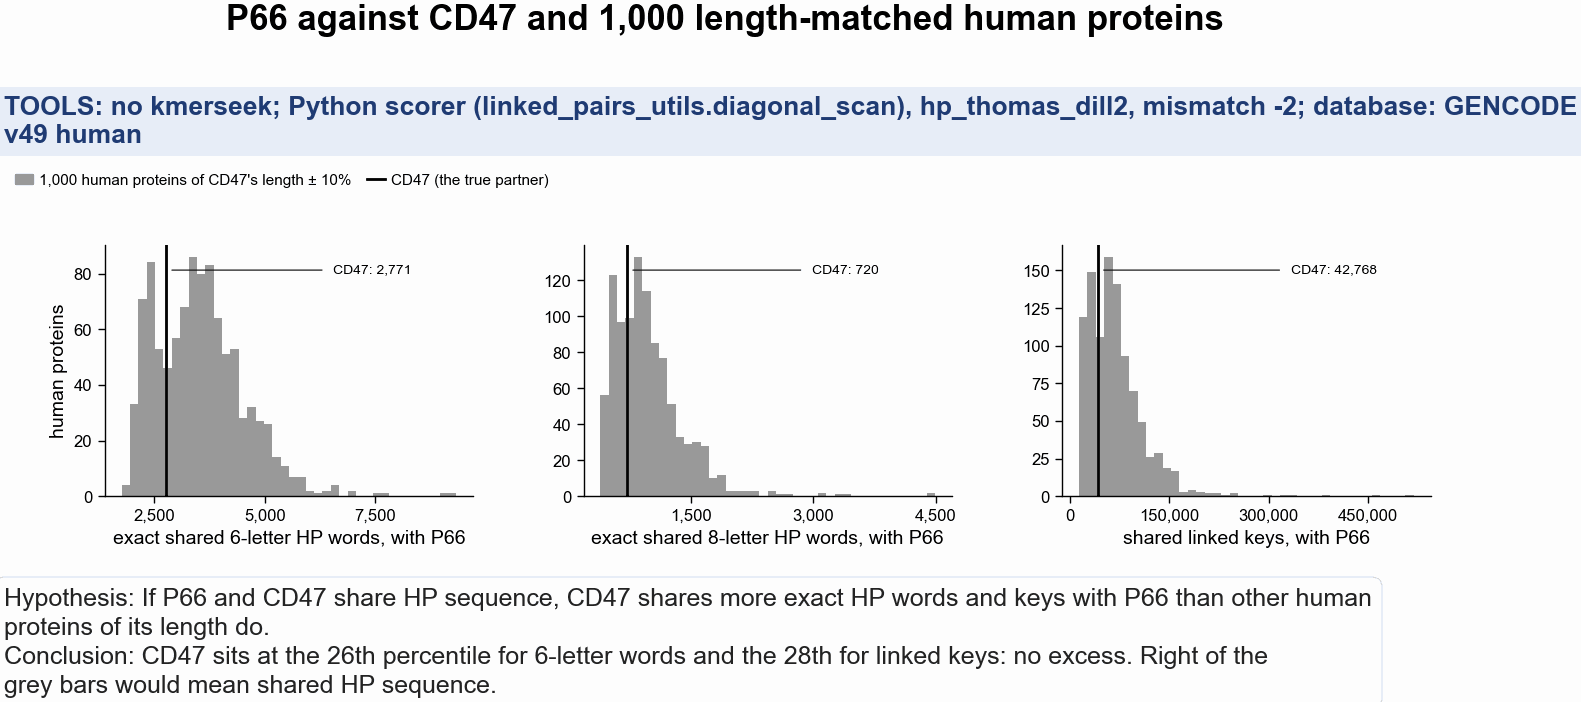

In [3]:
p66, p66_pre, cd47 = SEQ["P66_mature"], SEQ["P66_precursor"], SEQ["CD47"]
sig = int(V["P66_signal_peptide_length"])
lo = 181  # SIRPα-binding loop, mature numbering (Tal et al. 2024)
hi = 187
loop = p66[lo - 1 : hi]
assert loop == p66_pre[lo - 1 + sig : hi + sig]
print(
    f"P66 SIRPα-binding loop: mature {lo}-{hi} = precursor {lo + sig}-{hi + sig}: {loop}"
)
print(f"                        HP classes:                      {ku.classes(loop)}")

human = SCAN["human GENCODE v49 canonical"]
h_real = human.filter((pl.col("query") == "P66_mature") & (pl.col("kind") == "real"))
cd47_name = KNOWN.filter(pl.col("pair") == "pair 2")["partner"][0]
cd47_row = h_real.filter(pl.col("target") == cd47_name)
L_CD47 = len(cd47)
pool = h_real.filter(
    (pl.col("target") != cd47_name)
    & pl.col("length").is_between(0.9 * L_CD47, 1.1 * L_CD47)
)
N_MATCHED, SEED_MATCHED = 1_000, 346
matched = pool.sample(N_MATCHED, seed=SEED_MATCHED, shuffle=True)
rows = []
for col, label in [
    ("words6", "exact shared 6-letter HP words"),
    ("words8", "exact shared 8-letter HP words"),
    ("linked_count", "shared linked keys"),
]:
    v = int(cd47_row[col][0])
    m = matched[col].to_numpy()
    pct = 100 * ((m < v).mean() + 0.5 * (m == v).mean())
    rows.append(
        {
            "count": label,
            "P66 vs CD47": v,
            "median of 1,000 length-matched": float(np.median(m)),
            "CD47 percentile": round(pct, 1),
        }
    )
p66_counts = pl.DataFrame(rows)
print(
    f"P66 (mature, {len(p66)} aa) against CD47 ({L_CD47} aa) and against {N_MATCHED:,} human proteins of "
    f"{int(np.ceil(0.9 * L_CD47))}-{int(np.floor(1.1 * L_CD47))} aa (pool {pool.height:,}, seed {SEED_MATCHED}); "
    "percentile = share below CD47 plus half the ties:"
)
print(p66_counts)
p66_best = lp.best_keys_with_segments(p66, cd47)
b = p66_best["linked"]
print(
    f"best linked key between P66 and CD47, any diagonal: score {b['score']}, anchors P66 {b['q1'] + 1} and {b['q2'] + 1}, "
    f"CD47 {b['t1'] + 1} and {b['t2'] + 1}"
)
p_rows = ku.key_rows(p66, cd47, b)
ku.print_block(
    p_rows[0],
    p_rows[1],
    "P66 mature",
    "CD47",
    p_rows[2],
    p_rows[3],
    {"linked": ku.residue_marks(p_rows[0], p_rows[1], p_rows[4])},
)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=3, layout=None)
fig.subplots_adjust(left=0.07, right=0.99, top=0.78, bottom=0.2, wspace=0.3)
for ax, (col, label) in zip(
    axs,
    [
        ("words6", "exact shared 6-letter HP words"),
        ("words8", "exact shared 8-letter HP words"),
        ("linked_count", "shared linked keys"),
    ],
):
    ax.hist(matched[col], bins=40, color=ku.COLOR["real"])
    v = int(cd47_row[col][0])
    ax.axvline(v, color=ku.COLOR["partner"], lw=1)
    ax.annotate(
        f"CD47: {v:,}",
        (v, ax.get_ylim()[1] * 0.9),
        xytext=(0.62, 0.9),
        textcoords="axes fraction",
        fontsize=5,
        va="center",
        arrowprops={"arrowstyle": "-", "lw": 0.4, "color": ku.COLOR["partner"]},
    )
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_, _: f"{x_:,.0f}"))
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_xlabel(f"{label}, with P66")
axs[0].set_ylabel("human proteins")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig.legend(
    handles=[
        Patch(
            color=ku.COLOR["real"],
            label=f"{N_MATCHED:,} human proteins of CD47's length ± 10%",
        ),
        Line2D([], [], color=ku.COLOR["partner"], label="CD47 (the true partner)"),
    ],
    loc="upper left",
    bbox_to_anchor=(0.0, 0.97),
    ncol=2,
    frameon=False,
    fontsize=5.5,
)
hc.finish_figure(
    fig,
    FIG / "346_p66_cd47_shared_words_vs_length_matched_human.png",
    tools=TOOL + "; database: GENCODE v49 human",
    hypothesis="If P66 and CD47 share HP sequence, CD47 shares more exact HP words and keys with P66 than other human proteins of its length do.",
    conclusion=f"CD47 sits at the {p66_counts['CD47 percentile'][0]:.0f}th percentile for 6-letter words and the {p66_counts['CD47 percentile'][2]:.0f}th for linked keys: no excess. Right of the grey bars would mean shared HP sequence.",
    title="P66 against CD47 and 1,000 length-matched human proteins",
    wrap=120,
    tight_layout=False,
)
b3 = p66_best["B3"]
print(
    f"best B3 key between P66 and CD47: score {b3['score']}, seed at P66 {min(b3['q1'], b3['q2']) + 1}, CD47 {min(b3['t1'], b3['t2']) + 1}"
)

### 1c. Pairs 3 to 6, Pfam seed pairs from notebook 294's report half

Chosen before any search by the rule in the task brief, from notebook 294's report half at
20–30% identity. Pairs 3 to 5 have the largest linked-key minus B2 score among pairs that B2
does not find and the linked key does; ties go to the higher linked score, then the lower
pair index. Pair 6 has the highest linked score among the pairs that the linked key finds
and neither phmmer nor MMseqs2 finds (E ≤ 0.01). "Finds" uses notebook 294's thresholds at a
false-positive rate of 0.001 per comparison, recomputed here (`scripts/make_346_inputs.py`).

In [4]:
print(
    f"notebook 294 thresholds, report half: B2 above {V['threshold_B2_report_half']:.0f}, linked key above "
    f"{V['threshold_linked_report_half']:.0f}; pairs found by the linked key and by neither aligner at 20-30%: "
    f"{V['n_linked_only_not_aligners_20_30']:.0f}"
)
print(
    PFAM.select(
        "pair",
        "family",
        "family_name",
        "query",
        "target",
        (pl.col("seqid_ali") * 100).round(1).alias("identity_%"),
        "B2_ext",
        "B3_ext",
        "all_a6_g32_none_ext",
        "why_chosen",
    )
)
pf_best = {}
for r in PFAM.iter_rows(named=True):
    qs, ts, al = lp.alignment_cells(r["qaln"], r["taln"])
    best = lp.best_keys_with_segments(qs, ts, al)
    pf_best[r["pair"]] = best
    qn, tn = r["query"].split("/")[0], r["target"].split("/")[0]
    qstart, tstart = int(r["query"].split("/")[1].split("-")[0]), int(
        r["target"].split("/")[1].split("-")[0]
    )
    print(
        f"\n{r['pair']}: {r['family']} {r['family_name']}, {100 * r['seqid_ali']:.1f}% identity"
    )
    ku.print_block(
        r["qaln"],
        r["taln"],
        qn,
        tn,
        qstart,
        tstart,
        {
            "linked": ku.residue_marks(r["qaln"], r["taln"], best["linked"]),
            "B3": ku.residue_marks(r["qaln"], r["taln"], best["B3"]),
        },
    )
    s = lp.scan_sequences(qs, ts, al)
    print(
        f"linked keys on this alignment {s['linked_count']}, best linked key {s['linked']}, B3 {s['B3']}, B2 {s['B2']}"
    )

notebook 294 thresholds, report half: B2 above 22, linked key above 30; pairs found by the linked key and by neither aligner at 20-30%: 139
shape: (4, 10)
┌────────┬─────────┬────────────────────────────────────────┬─────────────────────────┬────────────────────────┬────────────┬────────┬────────┬─────────────────────┬──────────────────────────────────┐
│ pair   ┆ family  ┆ family_name                            ┆ query                   ┆ target                 ┆ identity_% ┆ B2_ext ┆ B3_ext ┆ all_a6_g32_none_ext ┆ why_chosen                       │
│ ---    ┆ ---     ┆ ---                                    ┆ ---                     ┆ ---                    ┆ ---        ┆ ---    ┆ ---    ┆ ---                 ┆ ---                              │
│ str    ┆ str     ┆ str                                    ┆ str                     ┆ str                    ┆ f64        ┆ f64    ┆ f64    ┆ f64                 ┆ str                              │
╞════════╪═════════╪═════════════════════

**Figure 1. The best linked key on each pair, in residues.** How to read it: each panel is one pair, query on top, partner below, one square per
residue coloured by HP class. A black outline marks an identical residue. Black bars under
the partner mark exact shared HP words of 6 or more. The two vermillion bars above are the
best linked key's anchors, joined by a bracket that gives the gap. Reddish-purple bars at
the bottom are B3's segments: filled for the segment holding the 8-letter word, open for
the second segment. Pair 2 has no alignment; its panel shows the local alignment that its
best linked key implies, on two diagonals. What to decide from it: whether the linked key
lands where the two proteins share HP structure, or on runs that any two proteins share.

shape: (6, 6)
┌──────────────────────────────────────────┬───────────────┬─────────────┬───────────────┬──────────────┬──────────┐
│ panel                                    ┆ columns shown ┆ query start ┆ partner start ┆ linked marks ┆ B3 marks │
│ ---                                      ┆ ---           ┆ ---         ┆ ---           ┆ ---          ┆ ---      │
│ str                                      ┆ i64           ┆ i64         ┆ i64           ┆ i64          ┆ i64      │
╞══════════════════════════════════════════╪═══════════════╪═════════════╪═══════════════╪══════════════╪══════════╡
│ pair 1: CED-9 vs BCL-2, USalign structur ┆ 58            ┆ 160         ┆ 140           ┆ 4            ┆ 4        │
│ pair 2: P66 vs CD47, no alignment: the b ┆ 71            ┆ 225         ┆ 61            ┆ 4            ┆ 0        │
│ pair 3: PF18196 Chromodomain helicase DN ┆ 72            ┆ 923         ┆ 1030          ┆ 4            ┆ 0        │
│ pair 4: PF06974 WS/DGAT C-terminal domai ┆ 78   

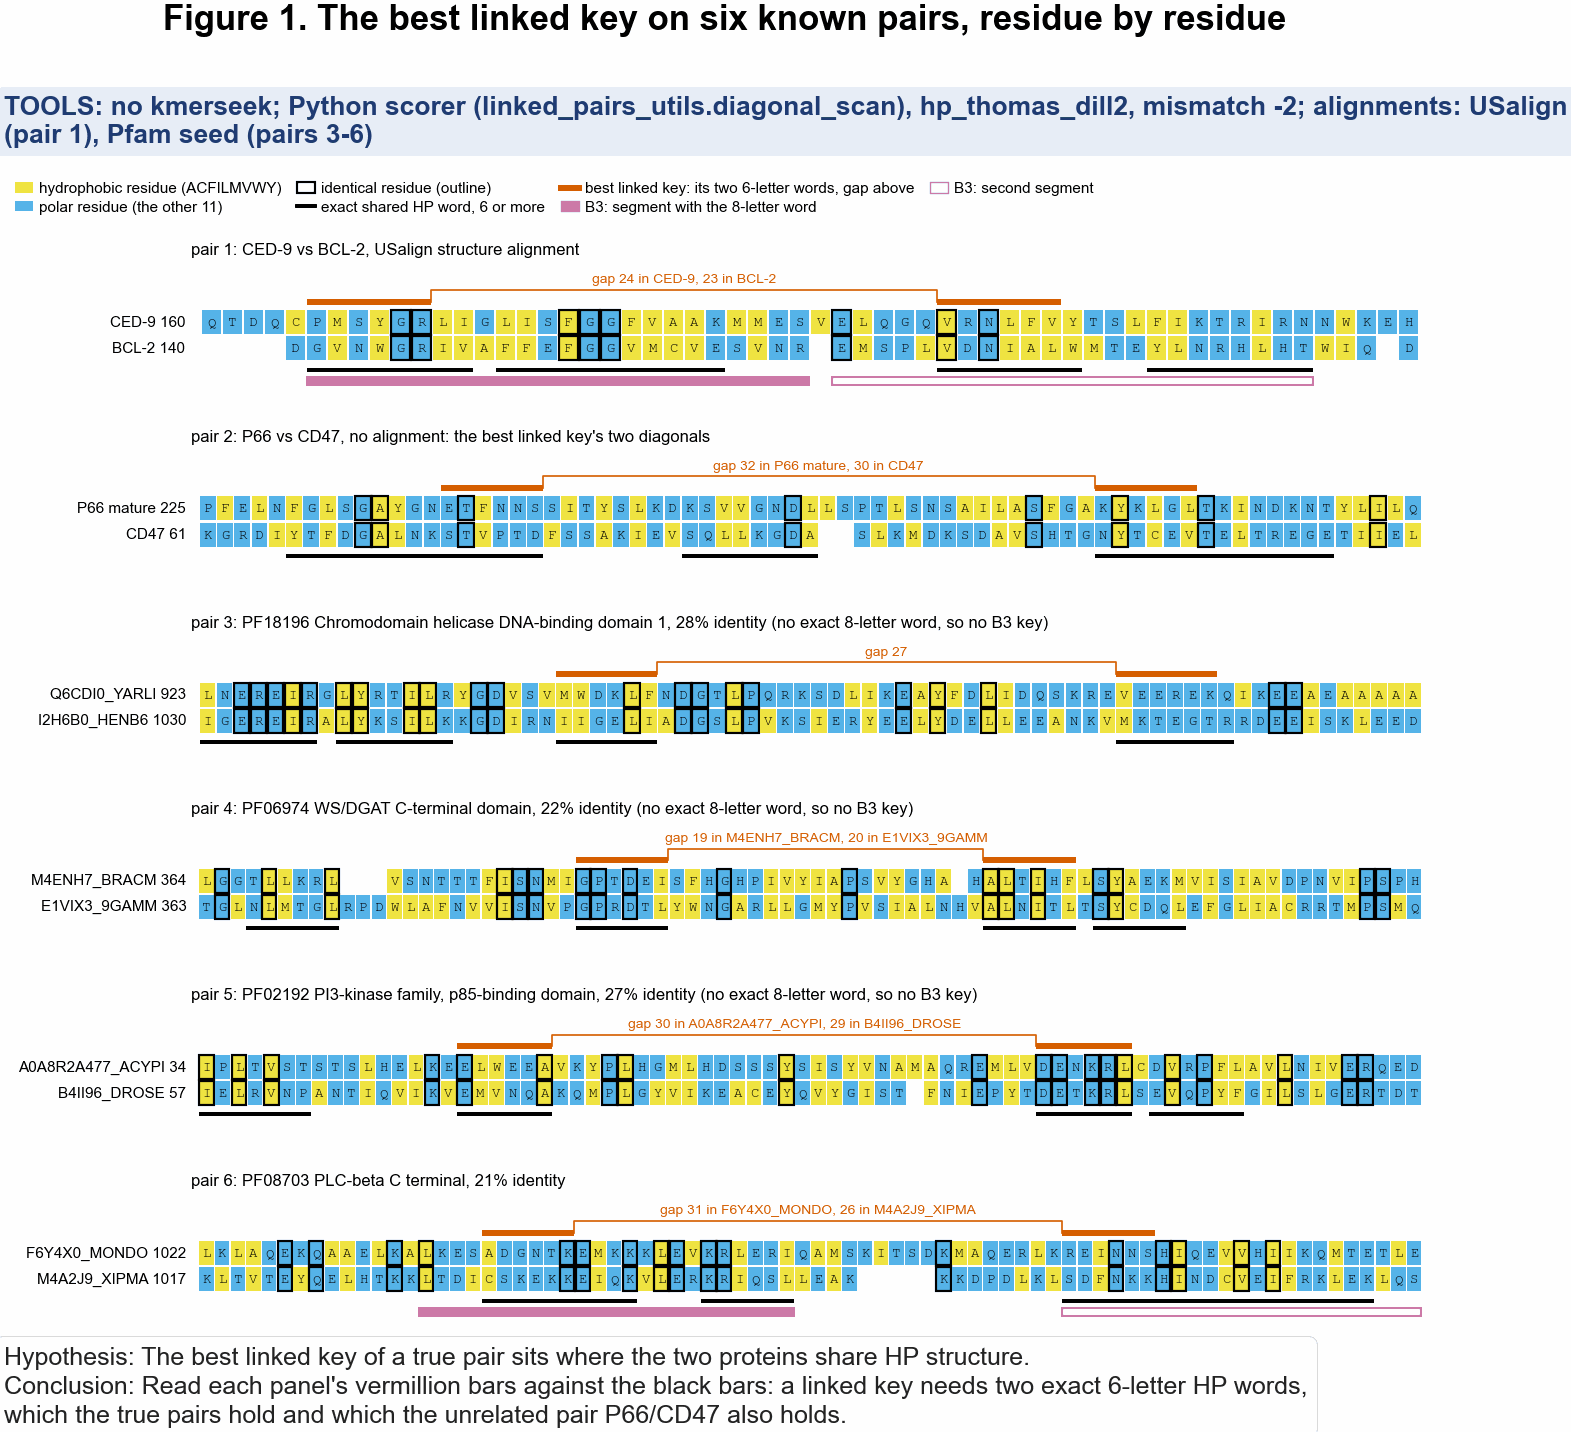

In [5]:
def window(qrow, marks, width=78):
    cols = [c for k in ("linked", "B3") for _, a, b in marks.get(k, []) for c in (a, b)]
    lo_, hi_ = max(0, min(cols) - 5), min(len(qrow), max(cols) + 6)
    if hi_ - lo_ > width:
        anchors = [
            c for k, a, b in marks["linked"] if k.startswith("anchor") for c in (a, b)
        ]
        mid = (min(anchors) + max(anchors)) // 2
        lo_, hi_ = max(0, mid - width // 2), min(len(qrow), mid + width // 2)
    return lo_, hi_


def cut(qrow, trow, q_start, t_start, marks, lo_, hi_):
    qs_ = q_start + sum(c != "-" for c in qrow[:lo_])
    ts_ = t_start + sum(c != "-" for c in trow[:lo_])
    # marks that run past the window are clipped to it (the linked key's anchors always fit)
    shifted = {
        k: [
            (n, max(a, lo_) - lo_, min(b, hi_ - 1) - lo_)
            for n, a, b in v
            if b >= lo_ and a < hi_
        ]
        for k, v in marks.items()
    }
    return qrow[lo_:hi_], trow[lo_:hi_], qs_, ts_, shifted


panels = [
    (
        "pair 1: CED-9 vs BCL-2, USalign structure alignment",
        q_aln,
        t_aln,
        "CED-9",
        "BCL-2",
        q0,
        t0,
        us_marks,
    )
]
panels.append(
    (
        "pair 2: P66 vs CD47, no alignment: the best linked key's two diagonals",
        p_rows[0],
        p_rows[1],
        "P66 mature",
        "CD47",
        p_rows[2],
        p_rows[3],
        {"linked": ku.residue_marks(p_rows[0], p_rows[1], p_rows[4])},
    )
)
for r in PFAM.iter_rows(named=True):
    best = pf_best[r["pair"]]
    mk = {
        "linked": ku.residue_marks(r["qaln"], r["taln"], best["linked"]),
        "B3": ku.residue_marks(r["qaln"], r["taln"], best["B3"]),
    }
    panels.append(
        (
            f"{r['pair']}: {r['family']} {r['family_name']}, {100 * r['seqid_ali']:.0f}% identity"
            + ("" if best["B3"] else " (no exact 8-letter word, so no B3 key)"),
            r["qaln"],
            r["taln"],
            r["query"].split("/")[0],
            r["target"].split("/")[0],
            int(r["query"].split("/")[1].split("-")[0]),
            int(r["target"].split("/")[1].split("-")[0]),
            mk,
        )
    )
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 150, nrows=len(panels), layout=None)
fig.subplots_adjust(left=0.13, right=0.99, top=0.90, bottom=0.01, hspace=0.55)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

handles = [
    Patch(facecolor=ku.COLOR["H"], label="hydrophobic residue (ACFILMVWY)"),
    Patch(facecolor=ku.COLOR["P"], label="polar residue (the other 11)"),
    Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        label="identical residue (outline)",
    ),
    Line2D([], [], color="black", lw=1.4, label="exact shared HP word, 6 or more"),
    Line2D(
        [],
        [],
        color=ku.COLOR["linked"],
        lw=2.2,
        label="best linked key: its two 6-letter words, gap above",
    ),
    Patch(
        facecolor=ku.COLOR["B3"],
        edgecolor=ku.COLOR["B3"],
        label="B3: segment with the 8-letter word",
    ),
    Patch(facecolor="white", edgecolor=ku.COLOR["B3"], label="B3: second segment"),
]
fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.0, 0.985),
    ncol=4,
    frameon=False,
    fontsize=5.5,
)
fig1_rows = []
for ax, (title, qrow, trow, qn, tn, qs_, ts_, marks) in zip(axs, panels):
    lo_, hi_ = window(qrow, marks)
    qr, tr, qs2, ts2, mk2 = cut(qrow, trow, qs_, ts_, marks, lo_, hi_)
    ku.draw_pair(
        ax,
        qr,
        tr,
        qn,
        tn,
        qs2,
        ts2,
        linked=mk2.get("linked"),
        b3=mk2.get("B3"),
        title=title,
    )
    fig1_rows.append(
        {
            "panel": title[:40],
            "columns shown": hi_ - lo_,
            "query start": qs2,
            "partner start": ts2,
            "linked marks": len(mk2.get("linked", [])),
            "B3 marks": len(mk2.get("B3", [])),
        }
    )
print(pl.DataFrame(fig1_rows))
hc.finish_figure(
    fig,
    FIG / "346_best_linked_key_residues_six_pairs.png",
    tools=TOOL + "; alignments: USalign (pair 1), Pfam seed (pairs 3-6)",
    hypothesis="The best linked key of a true pair sits where the two proteins share HP structure.",
    conclusion="Read each panel's vermillion bars against the black bars: a linked key needs two exact 6-letter HP words, which the true pairs hold and which the unrelated pair P66/CD47 also holds.",
    title="Figure 1. The best linked key on six known pairs, residue by residue",
    wrap=120,
    tight_layout=False,
)

## 2. The prediction and the rule, written before the search

Section 2 first puts the BCL-2/CED-9 pair in bits, from notebook 245's model and constants.
κ is the class copy rate of 20–30% identity Pfam pairs, measured in notebook 230: with
probability κ the partner copies the query's HP class, otherwise it draws a class at random.
The hydrophobic share h comes from the HP chance match rate h² + p² measured in notebook 241.
Each class pair scores s(a, b) = log₂ Pr(a, b) / (Pr(a) Pr(b)) bits.

In [6]:
cs = bu.chance_scores()
pr_match = dict(zip(cs["alphabet"], cs["pr_match_unrelated"]))[lp.ALPHABET]
assert pr_match == V["pr_match_unrelated_hp_thomas_dill2"]
kappa = V["kappa_hp_thomas_dill2_pfam_20_30"]
shares = bu.two_letter_shares(pr_match)
joint = bu.copy_rate_joint(shares, kappa)
bits = np.log2(
    joint / np.outer(shares, shares)
)  # rows: query class H, P; columns: partner class
print(
    f"κ = {kappa}, Pr(match by chance) = {pr_match}, so h = {shares[0]:.3f}, p = {shares[1]:.3f}"
)
print(
    f"bits per aligned position: h-h {bits[0, 0]:+.3f}, p-p {bits[1, 1]:+.3f}, h-p {bits[0, 1]:+.3f}"
)


def hp_bits(qrow, trow):
    return sum(
        bits[0 if a in ku.HYDROPHOBIC else 1, 0 if b in ku.HYDROPHOBIC else 1]
        for a, b in zip(qrow, trow)
        if a != "-" and b != "-" and a != "X" and b != "X"
    )


whole_bits = hp_bits(q_aln, t_aln)
key = us_best["linked"]
key_bits = sum(
    hp_bits(q_seq[s:e], t_seq[t : t + (e - s)]) for s, e, t in key["segments"]
)
key_len = sum(e - s for s, e, _ in key["segments"])
K, m, n = V["K_proteome"], len(ced9), V["n_residues_proteome"]
need = bu.bits_needed_region(K, m, n)
print(
    f"Best linked key plus its extension on the USalign alignment: {len(key['segments'])} segment(s), {key_len} positions, "
    f"{key_bits:.1f} bits. The whole {pairs245.height}-position alignment: {whole_bits:.1f} bits. "
    f"E = 1 against the human proteome needs log2(K·m·n) = log2({K} × {m} × {n:.3g}) = {need:.1f} bits "
    f"(K: Karlin-Altschul K borrowed from Swiss-Prot in notebook 245; m: CED-9's length; n: residues in one proteome)."
)
print(
    "The task brief quoted 22.9 bits for the whole alignment from notes; this model gives the number above "
    "(notebook 245's notebook does not print a whole-alignment total, so 22.9 is not reproduced here)."
)

κ = 0.463, Pr(match by chance) = 0.524, so h = 0.390, p = 0.610
bits per aligned position: h-h +0.785, p-p +0.375, h-p -0.897
Best linked key plus its extension on the USalign alignment: 2 segment(s), 47 positions, 19.9 bits. The whole 154-position alignment: 23.6 bits. E = 1 against the human proteome needs log2(K·m·n) = log2(0.018 × 280 × 1.1e+07) = 25.7 bits (K: Karlin-Altschul K borrowed from Swiss-Prot in notebook 245; m: CED-9's length; n: residues in one proteome).
The task brief quoted 22.9 bits for the whole alignment from notes; this model gives the number above (notebook 245's notebook does not print a whole-alignment total, so 22.9 is not reproduced here).


### Predictions and rule (copied from the task brief of 2026-10-18; not edited after section 3 ran)

The brief fixed these before any database search. A timing test on 2026-10-18 printed the
scores of BCL-2 and four other human proteins against CED-9; the rule was already fixed.

**Predictions**

- P1. CED-9 → human: BCL-2's rank under the linked key is worse than 10, under every HP scorer.
- P2. BCL-2's rank under the linked key is no better than under B3, in the same database with
  the same decoys.
- P3. The share of decoy proteins scoring at or above BCL-2 under the linked key is above 0.001.
- P4. P66 → human: CD47 is outside the top 1%, or, if inside, the share of decoys at or
  above it is above 0.01.
- P5. Of pairs 3 to 6, at most two keep a decoy rate at or below 0.001 at database scale
  under the linked key.

**Rule**, for "is a linked key worth anything at database scale that B3 is not":

- PASS: in at least one of the two directions (CED-9 → human, BCL-2 → *C. elegans*) the
  linked key ranks the true partner 10 or better with a decoy rate of 0.001 or below, and
  B3 does not.
- KILL: in both directions the linked key's rank is no better than B3's, or its decoy rate
  at the true partner's score is 0.01 or above.
- Unclear: anything else; say which number would settle it.

The P66/CD47 result cannot PASS. It only flags a key whose chance-match rate is too high.
Decoy rates use the dipeptide-preserving shuffle (b); the uniform shuffle (a) is reported
beside it.

## 3. The search

Every protein of each database is scored against the query as it is and as two decoys
(the shuffles a and b defined at the top), with the four scores on every diagonal, no alignment given.
The score of a protein is its best key. Swiss-Prot is searched by each Pfam pair's query
domain; the partner's domain (from the Pfam seed alignment) is added to Swiss-Prot as one
more protein, and any Swiss-Prot entry of the query's or the partner's own protein is left
out.

**Gate 1.** On the BCL-2/CED-9 USalign alignment, the database scorer restricted to the
alignment's own cells gives the same four scores (and key counts) as notebook 294's
per-pair scorer. **Gate 2.** On pairs 3 to 6, restricted to their Pfam seed alignment, it
gives the scores notebook 294 stored in `294_linked_pairs_scores.parquet`.

Gate 1, BCL-2/CED-9 USalign alignment:
shape: (6, 3)
┌──────────────────────┬─────────────────────┬──────────────────────────────────┐
│ score                ┆ notebook 294 scorer ┆ database scorer, alignment cells │
│ ---                  ┆ ---                 ┆ ---                              │
│ str                  ┆ f64                 ┆ f64                              │
╞══════════════════════╪═════════════════════╪══════════════════════════════════╡
│ B2                   ┆ 18.0                ┆ 18.0                             │
│ linked key           ┆ 32.0                ┆ 32.0                             │
│ randstrobe           ┆ 32.0                ┆ 32.0                             │
│ B3                   ┆ 32.0                ┆ 32.0                             │
│ linked key count     ┆ 92.0                ┆ 92.0                             │
│ randstrobe key count ┆ 4.0                 ┆ 4.0                              │
└──────────────────────┴─────────────────────

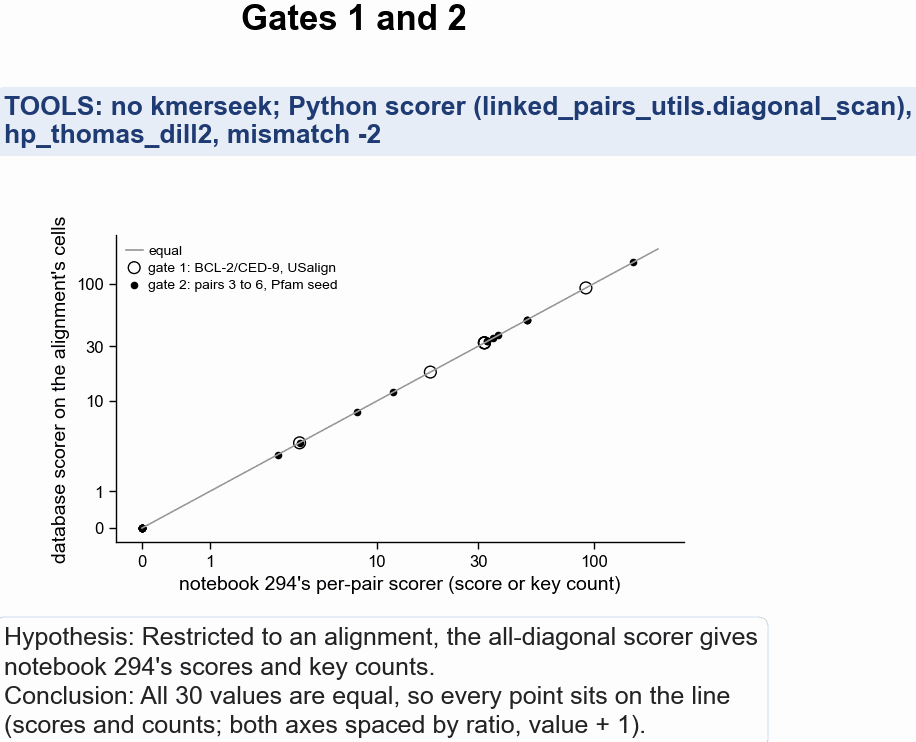

In [7]:
ref = lp.score_pair(q_aln, t_aln, np.random.default_rng(0), n_shuffle=0)[0]
LINKED = lp.setting_name("all", 6, 32, "none")
RAND = lp.setting_name("rand", 6, 32, "none")
gate1 = pl.DataFrame(
    [
        {
            "score": s,
            "notebook 294 scorer": float(ref[c]),
            "database scorer, alignment cells": float(us_scan[d]),
        }
        for s, c, d in [
            ("B2", "B2_ext", "B2"),
            ("linked key", f"{LINKED}_ext", "linked"),
            ("randstrobe", f"{RAND}_ext", "randstrobe"),
            ("B3", "B3_ext", "B3"),
            ("linked key count", f"{LINKED}_count", "linked_count"),
            ("randstrobe key count", f"{RAND}_count", "randstrobe_count"),
        ]
    ]
)
print("Gate 1, BCL-2/CED-9 USalign alignment:")
print(gate1)
assert (gate1["notebook 294 scorer"] == gate1["database scorer, alignment cells"]).all()

g2 = []
for r in PFAM.iter_rows(named=True):
    qs, ts, al = lp.alignment_cells(r["qaln"], r["taln"])
    s = lp.scan_sequences(qs, ts, al)
    for name, stored, mine in [
        ("B2", "B2_ext", "B2"),
        ("B3", "B3_ext", "B3"),
        ("linked key", f"{LINKED}_ext", "linked"),
        ("linked key count", f"{LINKED}_count", "linked_count"),
        ("randstrobe", f"{RAND}_ext", "randstrobe"),
        ("randstrobe key count", f"{RAND}_count", "randstrobe_count"),
    ]:
        g2.append(
            {
                "pair": r["pair"],
                "score": name,
                "stored by notebook 294": float(r[stored]),
                "database scorer": float(s[mine]),
            }
        )
gate2 = pl.DataFrame(g2)
print("Gate 2, pairs 3 to 6 on their Pfam seed alignments:")
print(gate2.pivot(on="pair", index="score", values="database scorer"))
assert (gate2["stored by notebook 294"] == gate2["database scorer"]).all()
print("Gates 1 and 2 hold: every value equal.")
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 60, layout=None)
fig.subplots_adjust(left=0.16, right=0.97, top=0.82, bottom=0.17)
gx = np.r_[
    gate1["notebook 294 scorer"].to_numpy(), gate2["stored by notebook 294"].to_numpy()
]
gy = np.r_[
    gate1["database scorer, alignment cells"].to_numpy(),
    gate2["database scorer"].to_numpy(),
]
gx1, gy1 = np.log10(gx + 1), np.log10(gy + 1)
ax.plot(
    [0, gx1.max() * 1.05],
    [0, gx1.max() * 1.05],
    color=ku.COLOR["real"],
    lw=0.6,
    label="equal",
)
ax.scatter(
    gx1[: gate1.height],
    gy1[: gate1.height],
    s=18,
    facecolors="none",
    edgecolors=ku.COLOR["partner"],
    label="gate 1: BCL-2/CED-9, USalign",
)
ax.scatter(
    gx1[gate1.height :],
    gy1[gate1.height :],
    s=5,
    color=ku.COLOR["partner"],
    label="gate 2: pairs 3 to 6, Pfam seed",
)
ticks = [0, 1, 10, 30, 100]
ax.set_xticks(np.log10(np.array(ticks) + 1), [str(t) for t in ticks])
ax.set_yticks(np.log10(np.array(ticks) + 1), [str(t) for t in ticks])
ax.set_xlabel("notebook 294's per-pair scorer (score or key count)")
ax.set_ylabel("database scorer on the alignment's cells")
ax.legend(loc="upper left", frameon=False, fontsize=5)
hc.finish_figure(
    fig,
    FIG / "346_gates_database_scorer_vs_nb294.png",
    tools=TOOL,
    hypothesis="Restricted to an alignment, the all-diagonal scorer gives notebook 294's scores and key counts.",
    conclusion=f"All {gx.size} values are equal, so every point sits on the line (scores and counts; both axes spaced by ratio, value + 1).",
    title="Gates 1 and 2",
    wrap=70,
    tight_layout=False,
)

In [8]:
def swissprot_keep(r):
    names = SCAN["Swiss-Prot"].filter(
        (pl.col("query") == r["query"]) & (pl.col("kind") == "real")
    )["target"]
    own = {r["query"].split("/")[0], r["partner"].split("/")[0]}
    partner_row = f"partner|{r['pair']}|{r['partner']}"
    keep = [
        t
        for t in names
        if not t.startswith("partner|") and t.split("|")[2].split()[0] not in own
    ] + [partner_row]
    return keep, partner_row


results, kept = [], {}
for r in KNOWN.iter_rows(named=True):
    if r["query_db"] not in SCAN:
        continue
    keep, partner = None, r["partner"]
    if r["query_db"] == "Swiss-Prot":
        keep, partner = swissprot_keep(r)
    kept[r["pair"]] = (keep, partner)
    t = ku.search_table(SCAN[r["query_db"]], r["query"], partner, keep)
    results.append(
        t.with_columns(
            pl.lit(r["pair"]).alias("pair"),
            pl.lit(r["query"]).alias("query"),
            pl.lit(r["query_db"]).alias("database"),
        )
    )
RES = pl.concat(results).select(
    "pair",
    "query",
    "database",
    "score",
    "partner_score",
    "rank",
    "n_real",
    "n_real_at_or_above",
    "decoy_rate_dipeptide",
    "decoy_rate_uniform",
    "partner_keys",
    "median_keys",
    "n_decoys_dipeptide",
    "n_decoys_uniform",
)
RES.write_csv(TAB / "346_ranks_and_decoy_rates.tsv", separator="\t")
h_ced9 = human.filter((pl.col("query") == "CED-9") & (pl.col("kind") == "real"))
failed = {
    db: int(s["shuffle_failed"].sum()) // max(1, s["query"].n_unique())
    for db, s in SCAN.items()
}
print("dipeptide shuffles that failed (left out of the decoys), per database:", failed)
print(
    "Rank of the true partner (ties against it), decoy rate under each shuffle, and key matches:"
)
print(
    RES.drop("n_decoys_dipeptide", "n_decoys_uniform").with_columns(
        pl.col("decoy_rate_dipeptide", "decoy_rate_uniform").round(4)
    )
)
missing = [r["pair"] for r in KNOWN.iter_rows(named=True) if r["query_db"] not in SCAN]
if missing:
    print(
        f"\nNot run yet: {', '.join(missing)} (Swiss-Prot scan, scripts/346_swissprot_scan.sbatch on Sherlock)."
    )

dipeptide shuffles that failed (left out of the decoys), per database: {'human GENCODE v49 canonical': 8, 'C. elegans UniProt UP000001940': 46, 'B. burgdorferi B31 UniProt UP000001807': 0}
Rank of the true partner (ties against it), decoy rate under each shuffle, and key matches:
shape: (20, 12)
┌──────────────────────┬────────────┬──────────────────────┬────────────┬───────────────┬───────┬────────┬────────────────────┬──────────────────────┬────────────────────┬──────────────┬─────────────┐
│ pair                 ┆ query      ┆ database             ┆ score      ┆ partner_score ┆ rank  ┆ n_real ┆ n_real_at_or_above ┆ decoy_rate_dipeptide ┆ decoy_rate_uniform ┆ partner_keys ┆ median_keys │
│ ---                  ┆ ---        ┆ ---                  ┆ ---        ┆ ---           ┆ ---   ┆ ---    ┆ ---                ┆ ---                  ┆ ---                ┆ ---          ┆ ---         │
│ str                  ┆ str        ┆ str                  ┆ str        ┆ i64           ┆ i64   ┆ i6

**Figure 2. Scores of every database protein, every decoy and the true partner.** How to read it: one column per search direction, one row per score. Each line is the share
of proteins scoring at or above a given score: grey for the real database proteins, green
for decoys from the uniform shuffle, blue for decoys from the dipeptide-preserving shuffle.
The black vertical line is the true partner's score, with its rank. The vertical axis is
spaced by ratio: the step from 1 to 0.1 takes as much room as the step from 0.01 to 0.001.
Where the black line crosses the blue curve is the decoy rate. A key worth having would put
the black line far right of the grey and blue curves, where they have fallen below 0.001.

shape: (20, 6)
┌──────────────────────┬────────────┬───────────────┬───────┬────────────────────────┬────────┐
│ direction            ┆ score      ┆ partner score ┆ rank  ┆ decoy rate (dipeptide) ┆ n real │
│ ---                  ┆ ---        ┆ ---           ┆ ---   ┆ ---                    ┆ ---    │
│ str                  ┆ str        ┆ i64           ┆ i64   ┆ f64                    ┆ i64    │
╞══════════════════════╪════════════╪═══════════════╪═══════╪════════════════════════╪════════╡
│ pair 1               ┆ B2         ┆ 24            ┆ 8805  ┆ 0.4207                 ┆ 19732  │
│ pair 1               ┆ linked     ┆ 37            ┆ 9952  ┆ 0.4807                 ┆ 19732  │
│ pair 1               ┆ randstrobe ┆ 37            ┆ 5451  ┆ 0.2554                 ┆ 19732  │
│ pair 1               ┆ B3         ┆ 37            ┆ 10798 ┆ 0.5229                 ┆ 19732  │
│ pair 1, SCOPe domain ┆ B2         ┆ 22            ┆ 7060  ┆ 0.354                  ┆ 19732  │
│ pair 1, SCOPe domain ┆ 

Figure 2b (pairs 3 to 6 against Swiss-Prot) waits on the Sherlock scan.


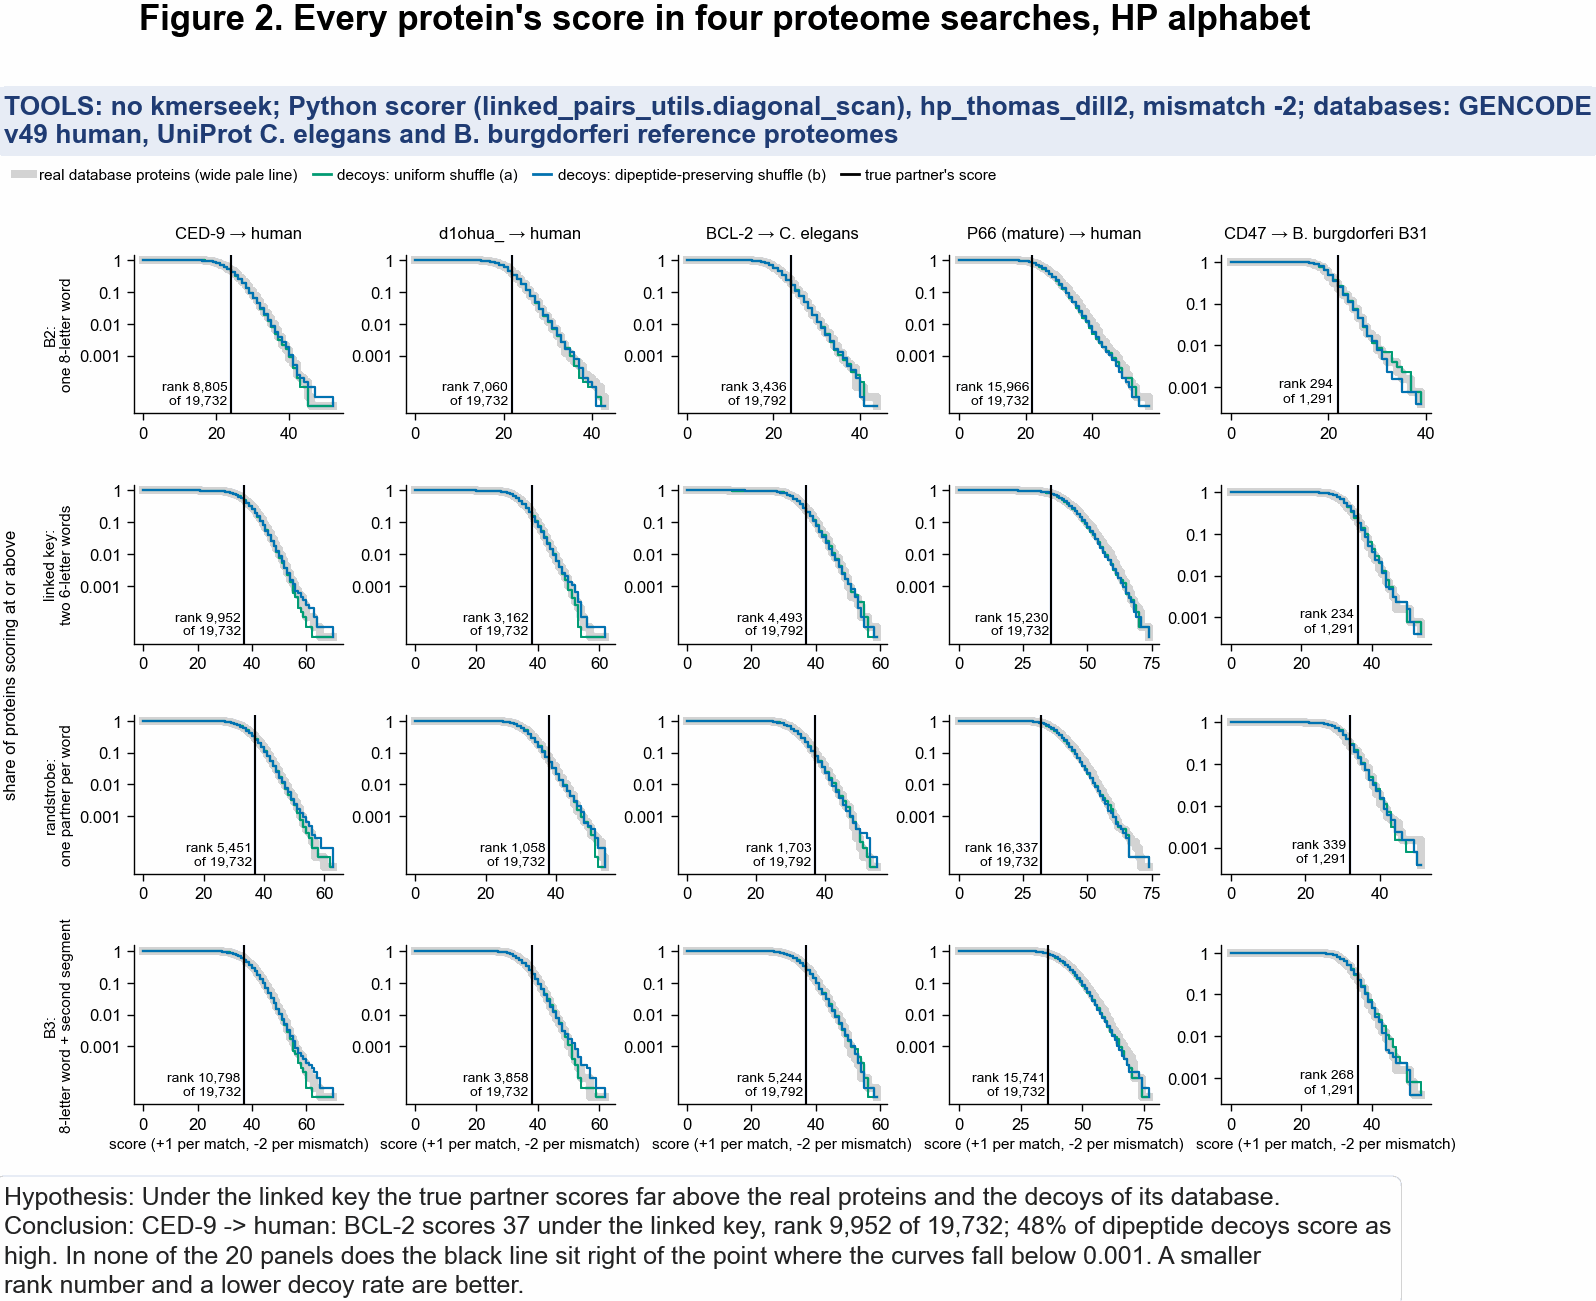

In [9]:
def survival(v, grid):
    v = np.sort(v)
    return 1 - np.searchsorted(v, grid, side="left") / v.size


def figure2(directions, path, title):
    fig, axs = pf.figure(
        pf.TWO_COLUMN_MM,
        30 + 25 * len(ku.SCORES),
        nrows=len(ku.SCORES),
        ncols=len(directions),
        layout=None,
        squeeze=False,
    )
    fig.subplots_adjust(
        left=0.09, right=0.99, top=0.90, bottom=0.07, hspace=0.45, wspace=0.3
    )
    shown = []
    for j, r in enumerate(directions):
        d = SCAN[r["query_db"]].filter(pl.col("query") == r["query"])
        keep, partner = kept[r["pair"]]
        if keep is not None:
            d = d.filter(pl.col("target").is_in(keep))
        for i, s in enumerate(ku.SCORES):
            ax = axs[i, j]
            real = d.filter(pl.col("kind") == "real")
            grid = np.arange(0, int(d[s].max()) + 2)
            for kind, lw, alpha in [
                ("real", 3.0, 0.45),
                ("uniform", 0.8, 1.0),
                ("dipeptide", 0.8, 1.0),
            ]:
                v = d.filter(
                    (pl.col("kind") == kind) & (pl.col("shuffle_failed") == 0)
                )[s].to_numpy()
                ax.step(
                    grid,
                    np.maximum(survival(v, grid), 0.5 / v.size),
                    where="post",
                    color=ku.COLOR[kind],
                    lw=lw,
                    alpha=alpha,
                )
            row = RES.filter(
                (pl.col("pair") == r["pair"]) & (pl.col("score") == s)
            ).row(0, named=True)
            ax.axvline(row["partner_score"], color=ku.COLOR["partner"], lw=0.8)
            ax.text(
                row["partner_score"] - 1,
                0.5 / max(real.height, 1000),
                f"rank {row['rank']:,}\nof {row['n_real']:,}",
                fontsize=5,
                va="bottom",
                ha="right",
            )
            ax.set_yscale("log")
            ax.set_ylim(0.3 / max(real.height, 1000), 1.5)
            ax.set_yticks([1, 0.1, 0.01, 0.001], ["1", "0.1", "0.01", "0.001"])
            ax.minorticks_off()
            if i == 0:
                qlab = {"P66_mature": "P66 (mature)"}.get(
                    r["query"], r["query"].split("/")[0]
                )
                ax.set_title(
                    f"{qlab} → {r['query_db'].split(' UniProt')[0].replace(' GENCODE v49 canonical', '')}",
                    fontsize=6,
                )
            if j == 0:
                ax.set_ylabel(ku.SCORE_LABEL[s].replace(": ", ":\n"), fontsize=5.5)
            if i == len(ku.SCORES) - 1:
                ax.set_xlabel("score (+1 per match, -2 per mismatch)", fontsize=5.5)
            shown.append(
                {
                    "direction": r["pair"],
                    "score": s,
                    "partner score": row["partner_score"],
                    "rank": row["rank"],
                    "decoy rate (dipeptide)": round(row["decoy_rate_dipeptide"], 4),
                    "n real": real.height,
                }
            )
    handles = [
        Line2D(
            [],
            [],
            color=ku.COLOR["real"],
            lw=3,
            alpha=0.45,
            label="real database proteins (wide pale line)",
        ),
        Line2D([], [], color=ku.COLOR["uniform"], label="decoys: uniform shuffle (a)"),
        Line2D(
            [],
            [],
            color=ku.COLOR["dipeptide"],
            label="decoys: dipeptide-preserving shuffle (b)",
        ),
        Line2D([], [], color=ku.COLOR["partner"], label="true partner's score"),
    ]
    fig.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0.0, 0.995),
        ncol=4,
        frameon=False,
        fontsize=5.5,
    )
    fig.text(
        0.0,
        0.5,
        "share of proteins scoring at or above",
        rotation=90,
        va="center",
        fontsize=6,
    )
    print(pl.DataFrame(shown))
    return fig


prot = [
    r
    for r in KNOWN.iter_rows(named=True)
    if r["query_db"] != "Swiss-Prot" and r["query_db"] in SCAN
]
fig = figure2(prot, FIG / "346_score_distributions_proteomes.png", "")
c = RES.filter((pl.col("pair") == "pair 1") & (pl.col("score") == "linked")).row(
    0, named=True
)
hc.finish_figure(
    fig,
    FIG / "346_score_distributions_proteomes.png",
    tools=TOOL
    + "; databases: GENCODE v49 human, UniProt C. elegans and B. burgdorferi reference proteomes",
    hypothesis="Under the linked key the true partner scores far above the real proteins and the decoys of its database.",
    conclusion=(
        f"CED-9 -> human: BCL-2 scores {c['partner_score']} under the linked key, rank {c['rank']:,} of {c['n_real']:,}; "
        f"{100 * c['decoy_rate_dipeptide']:.0f}% of dipeptide decoys score as high. In none of the 20 panels does the black line "
        "sit right of the point where the curves fall below 0.001. A smaller rank number and a lower decoy rate are better."
    ),
    title="Figure 2. Every protein's score in four proteome searches, HP alphabet",
    wrap=120,
    tight_layout=False,
)
if "Swiss-Prot" in SCAN:
    sp = [r for r in KNOWN.iter_rows(named=True) if r["query_db"] == "Swiss-Prot"]
    fig = figure2(sp, FIG / "346_score_distributions_swissprot.png", "")
    hc.finish_figure(
        fig,
        FIG / "346_score_distributions_swissprot.png",
        tools=TOOL + "; database: Swiss-Prot",
        hypothesis="Under the linked key the Pfam partner domain scores far above Swiss-Prot and its decoys.",
        conclusion="See the table above each figure for the decoy rates; lower is better.",
        title="Figure 2b. Pairs 3 to 6 against Swiss-Prot, HP alphabet",
        wrap=120,
        tight_layout=False,
    )
else:
    print("Figure 2b (pairs 3 to 6 against Swiss-Prot) waits on the Sherlock scan.")

**Figure 3. Chance key matches per protein pair, against the database protein's length.** How to read it: one point per human protein, CED-9 as the query, real proteins only; the
vertical position is how many keys of each kind the two proteins share over every diagonal.
The stars are notebook 294's counts per pair of unrelated 131-residue proteins on one
diagonal only, the number PR 143 could measure. Both axes are spaced by ratio. B2's
squares and the randstrobe's triangles overlap because the two counts are nearly equal. What to
decide from it: how many chance matches each key costs a search before any score is
computed. A key that matches thousands of times per protein pair cannot be looked up one
match at a time.

shape: (4, 3)
┌──────────────────────────────────┬─────────────────────────────────┬───────────────────────────────────┐
│ key                              ┆ median per protein (all 19,732) ┆ median per 100 residues of target │
│ ---                              ┆ ---                             ┆ ---                               │
│ str                              ┆ f64                             ┆ f64                               │
╞══════════════════════════════════╪═════════════════════════════════╪═══════════════════════════════════╡
│ B2's 8-letter words (squares)    ┆ 590.0                           ┆ 140.258075                        │
│ B3 keys                          ┆ 608597.0                        ┆ 144010.544218                     │
│ linked keys                      ┆ 41720.5                         ┆ 9875.457889                       │
│ randstrobe keys (open triangles) ┆ 617.5                           ┆ 148.086778                        │
└──────────────────────

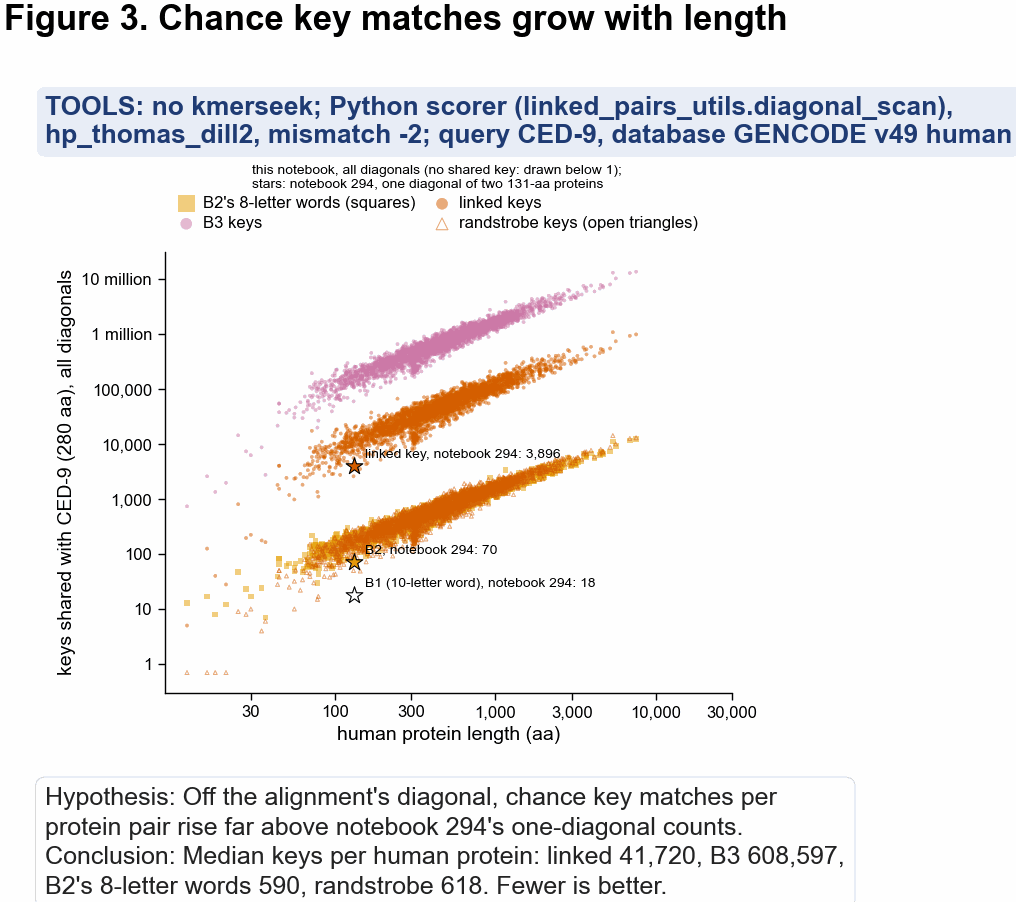

In [10]:
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80, layout=None)
fig.subplots_adjust(left=0.17, right=0.98, top=0.84, bottom=0.14)
rng = np.random.default_rng(346)
idx = rng.choice(h_ced9.height, 3_000, replace=False)
sub = h_ced9[np.sort(idx)]
spec = [
    ("words8", "B2's 8-letter words (squares)", "B2", "s", True),
    ("B3_count", "B3 keys", "B3", "o", True),
    ("linked_count", "linked keys", "linked", "o", True),
    ("randstrobe_count", "randstrobe keys (open triangles)", "linked", "^", False),
]
f3 = []
for col, label, colour, marker, filled in spec:
    y = sub[col].to_numpy().astype(float)
    ax.scatter(
        sub["length"],
        np.where(y > 0, y, 0.7),
        s=4 if marker == "s" else 2,
        marker=marker,
        color=ku.COLOR[colour] if filled else "none",
        edgecolors="none" if filled else ku.COLOR[colour],
        linewidths=0.4,
        alpha=0.5,
        label=label,
        rasterized=True,
    )
    f3.append(
        {
            "key": label,
            "median per protein (all 19,732)": float(h_ced9[col].median()),
            "median per 100 residues of target": float(
                (h_ced9[col] / h_ced9["length"] * 100).median()
            ),
        }
    )
for q, label, colour, marker in [
    ("chance_keys_linked_per_131", "linked key, notebook 294", "linked", "*"),
    ("chance_keys_B2_per_131", "B2, notebook 294", "B2", "*"),
    ("chance_keys_B1_per_131", "B1 (10-letter word), notebook 294", None, "*"),
]:
    ax.scatter(
        [V["chance_keys_pair_length"]],
        [V[q]],
        s=40,
        marker=marker,
        color=ku.COLOR[colour] if colour else "white",
        edgecolors="black",
        linewidths=0.4,
        zorder=5,
    )
    ax.annotate(
        f"{label}: {V[q]:,.0f}",
        (V["chance_keys_pair_length"], V[q]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=5,
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(
    [30, 100, 300, 1000, 3000, 10_000, 30_000],
    ["30", "100", "300", "1,000", "3,000", "10,000", "30,000"],
)
ax.set_yticks(
    [1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7],
    ["1", "10", "100", "1,000", "10,000", "100,000", "1 million", "10 million"],
)
ax.minorticks_off()
ax.set_xlabel("human protein length (aa)")
ax.set_ylabel("keys shared with CED-9 (280 aa), all diagonals")
leg = ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False,
    markerscale=3,
    title="this notebook, all diagonals (no shared key: drawn below 1);\nstars: notebook 294, one diagonal of two 131-aa proteins",
    title_fontsize=5,
)
print(pl.DataFrame(f3))
hc.finish_figure(
    fig,
    FIG / "346_chance_key_matches_vs_length_human.png",
    tools=TOOL + "; query CED-9, database GENCODE v49 human",
    hypothesis="Off the alignment's diagonal, chance key matches per protein pair rise far above notebook 294's one-diagonal counts.",
    conclusion=(
        f"Median keys per human protein: linked {h_ced9['linked_count'].median():,.0f}, B3 {h_ced9['B3_count'].median():,.0f}, "
        f"B2's 8-letter words {h_ced9['words8'].median():,.0f}, randstrobe {h_ced9['randstrobe_count'].median():,.0f}. Fewer is better."
    ),
    title="Figure 3. Chance key matches grow with length",
    wrap=70,
    tight_layout=False,
)

### Where BCL-2's best key sits

BCL-2's database-scale score is its best key over every diagonal of the two whole
sequences. If that key lies off the structure alignment, the score is not evidence of the
shared fold.

Best keys between the whole CED-9 and BCL-2 sequences, any diagonal (residue numbers 1-based):
shape: (4, 7)
┌────────┬───────────┬─────────┬───────┬────────┬───────────────┬──────────────────────────┐
│ score  ┆ key score ┆ segment ┆ CED-9 ┆ BCL-2  ┆ residue pairs ┆ on the USalign alignment │
│ ---    ┆ ---       ┆ ---     ┆ ---   ┆ ---    ┆ ---           ┆ ---                      │
│ str    ┆ i64       ┆ i64     ┆ str   ┆ str    ┆ i64           ┆ i64                      │
╞════════╪═══════════╪═════════╪═══════╪════════╪═══════════════╪══════════════════════════╡
│ linked ┆ 37        ┆ 1       ┆ 7-22  ┆ 53-68  ┆ 16            ┆ 0                        │
│ linked ┆ 37        ┆ 2       ┆ 23-85 ┆ 87-149 ┆ 63            ┆ 0                        │
│ B3     ┆ 37        ┆ 1       ┆ 7-22  ┆ 53-68  ┆ 16            ┆ 0                        │
│ B3     ┆ 37        ┆ 2       ┆ 23-85 ┆ 87-149 ┆ 63            ┆ 0                        │
└────────┴───────────┴─────────┴───────┴────────┴─────

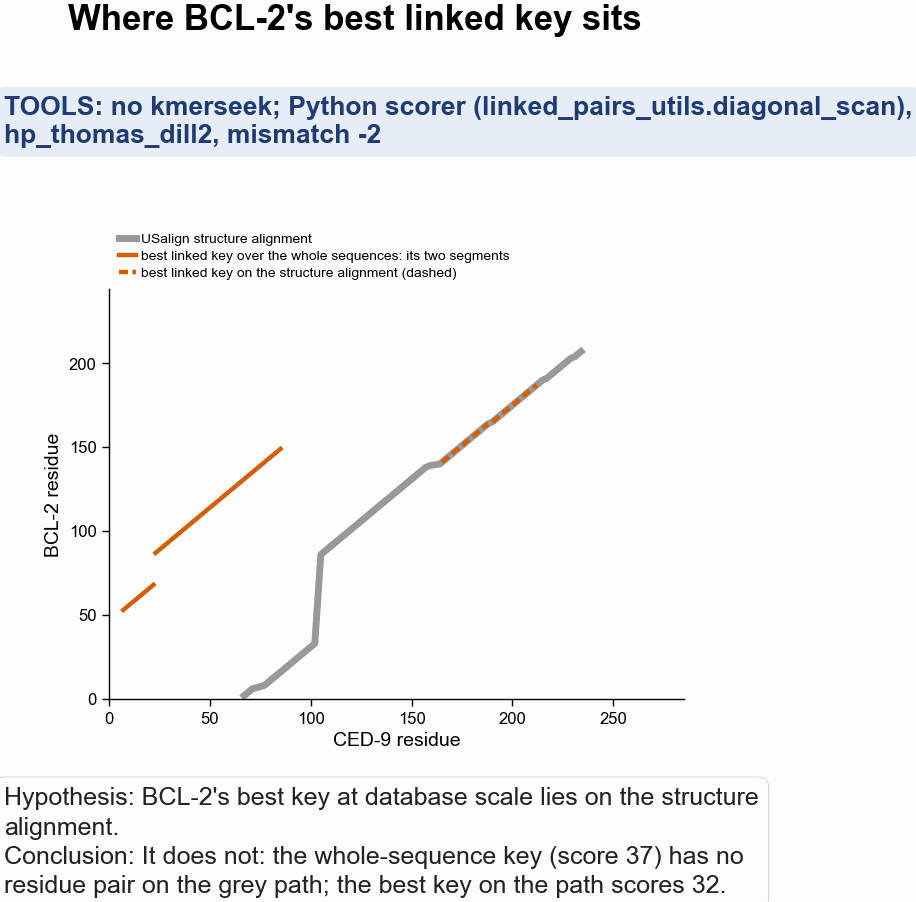

In [11]:
whole_best = lp.best_keys_with_segments(ced9, bcl2)
on_aln = set(zip(pairs245["ced9_pos"], pairs245["bcl2_pos"]))
wb_rows = []
for name in ["linked", "B3"]:
    x = whole_best[name]
    for k, (s0, e0, t_s) in enumerate(x["segments"]):
        n_on = sum((s0 + i + 1, t_s + i + 1) in on_aln for i in range(e0 - s0))
        wb_rows.append(
            {
                "score": name,
                "key score": x["score"],
                "segment": k + 1,
                "CED-9": f"{s0 + 1}-{e0}",
                "BCL-2": f"{t_s + 1}-{t_s + e0 - s0}",
                "residue pairs": e0 - s0,
                "on the USalign alignment": n_on,
            }
        )
WB = pl.DataFrame(wb_rows)
print(
    "Best keys between the whole CED-9 and BCL-2 sequences, any diagonal (residue numbers 1-based):"
)
print(WB)
print(
    f"On the structure alignment alone the best linked key scores {us_scan['linked']}; the whole-sequence key "
    f"scores {whole_best['linked']['score']} with {WB.filter(pl.col('score') == 'linked')['on the USalign alignment'].sum()} "
    "of its residue pairs on the alignment."
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80, layout=None)
fig.subplots_adjust(left=0.15, right=0.97, top=0.78, bottom=0.13)
ax.plot(
    pairs245["ced9_pos"],
    pairs245["bcl2_pos"],
    color=ku.COLOR["real"],
    lw=2.5,
    label="USalign structure alignment",
)
for k_, (s0, e0, t_s) in enumerate(whole_best["linked"]["segments"]):
    ax.plot(
        [s0 + 1, e0],
        [t_s + 1, t_s + e0 - s0],
        color=ku.COLOR["linked"],
        lw=1.6,
        label=(
            "best linked key over the whole sequences: its two segments"
            if k_ == 0
            else None
        ),
    )
x = us_best["linked"]
for k_, (s0, e0, t_s) in enumerate(x["segments"]):
    ax.plot(
        [s0 + q0, e0 + q0 - 1],
        [t_s + t0, t_s + t0 + e0 - s0 - 1],
        color=ku.COLOR["linked"],
        lw=1.6,
        ls=(0, (2, 1)),
        label=(
            "best linked key on the structure alignment (dashed)" if k_ == 0 else None
        ),
    )
ax.set_xlim(0, len(ced9) + 5)
ax.set_ylim(0, len(bcl2) + 5)
ax.set_xlabel("CED-9 residue")
ax.set_ylabel("BCL-2 residue")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=5)
hc.finish_figure(
    fig,
    FIG / "346_bcl2_ced9_best_key_vs_structure_alignment.png",
    tools=TOOL,
    hypothesis="BCL-2's best key at database scale lies on the structure alignment.",
    conclusion=f"It does not: the whole-sequence key (score {whole_best['linked']['score']}) has no residue pair on the grey path; the best key on the path scores {us_scan['linked']}.",
    title="Where BCL-2's best linked key sits",
    wrap=70,
    tight_layout=False,
)

### Who ranks above BCL-2? The top 20 human proteins for CED-9 under the linked key

A ranking that puts the true partner at rank 9,000 should say what is on top. If the top
hits are long proteins with nothing in common with CED-9, the score is counting chance key
matches, which grow with the target's length.

shape: (20, 6)
┌─────────────────┬────────┬────────┬─────┬─────┬──────────────┐
│ gene            ┆ length ┆ linked ┆ B3  ┆ B2  ┆ linked_count │
│ ---             ┆ ---    ┆ ---    ┆ --- ┆ --- ┆ ---          │
│ str             ┆ i64    ┆ i64    ┆ i64 ┆ i64 ┆ i64          │
╞═════════════════╪════════╪════════╪═════╪═════╪══════════════╡
│ SIX3            ┆ 332    ┆ 64     ┆ 64  ┆ 39  ┆ 44146        │
│ HECTD4          ┆ 4418   ┆ 62     ┆ 62  ┆ 40  ┆ 427770       │
│ LMAN1           ┆ 510    ┆ 59     ┆ 59  ┆ 41  ┆ 64535        │
│ ZNF800          ┆ 664    ┆ 59     ┆ 59  ┆ 35  ┆ 88848        │
│ TBC1D5          ┆ 817    ┆ 59     ┆ 59  ┆ 31  ┆ 96946        │
│ BNIP5           ┆ 652    ┆ 58     ┆ 58  ┆ 43  ┆ 91586        │
│ ENSG00000283782 ┆ 1213   ┆ 58     ┆ 58  ┆ 37  ┆ 201385       │
│ RAD50           ┆ 1312   ┆ 58     ┆ 58  ┆ 37  ┆ 209835       │
│ DMD             ┆ 3685   ┆ 58     ┆ 58  ┆ 35  ┆ 523013       │
│ TTC6            ┆ 1886   ┆ 57     ┆ 57  ┆ 32  ┆ 184209       │
│ FCN1    

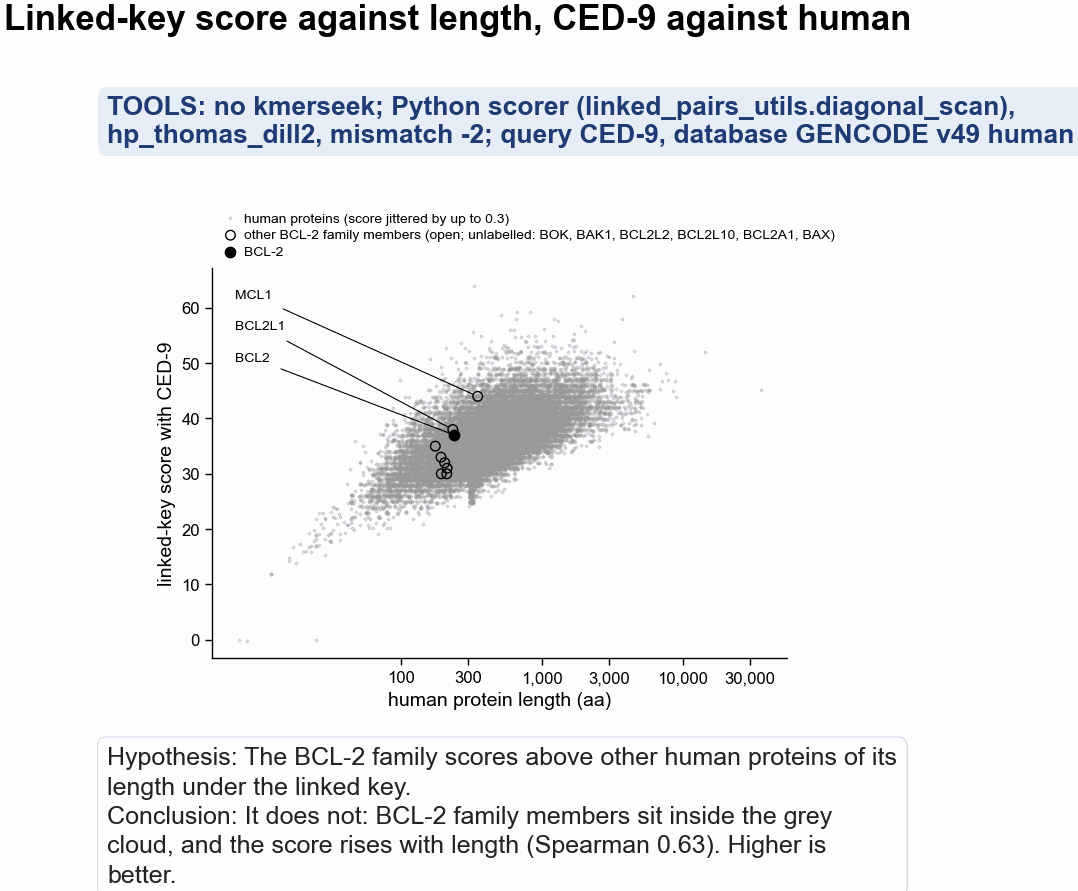

In [12]:
gene = pl.col("target").str.split("|").list.get(6)
top = (
    h_ced9.with_columns(gene.alias("gene"))
    .sort(["linked", "length"], descending=[True, False])
    .head(20)
    .select("gene", "length", "linked", "B3", "B2", "linked_count")
)
print(top)
BCL2_FAMILY = [
    "BCL2",
    "BCL2L1",
    "BCL2L2",
    "MCL1",
    "BCL2A1",
    "BCL2L10",
    "BAX",
    "BAK1",
    "BOK",
]
fam = h_ced9.with_columns(gene.alias("gene")).filter(pl.col("gene").is_in(BCL2_FAMILY))
fam_rank = fam.with_columns(
    (
        1
        + pl.col("linked").map_elements(
            lambda v: int((h_ced9["linked"] > v).sum()), return_dtype=pl.Int64
        )
    ).alias("best_possible_rank")
)
print(
    "BCL-2 family members (multidomain BCL-2-like and BAX/BAK/BOK) in the human proteome, linked-key score and rank if ties went their way:"
)
print(
    fam_rank.select("gene", "length", "linked", "B3", "best_possible_rank").sort(
        "linked", descending=True
    )
)
rho = np.corrcoef(
    np.argsort(np.argsort(h_ced9["length"].to_numpy())),
    np.argsort(np.argsort(h_ced9["linked"].to_numpy())),
)[0, 1]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75, layout=None)
fig.subplots_adjust(left=0.15, right=0.97, top=0.80, bottom=0.14)
ax.scatter(
    h_ced9["length"],
    h_ced9["linked"] + np.random.default_rng(0).uniform(-0.3, 0.3, h_ced9.height),
    s=1,
    color=ku.COLOR["real"],
    alpha=0.3,
    rasterized=True,
    label="human proteins (score jittered by up to 0.3)",
)
fr = fam_rank.with_columns(pl.col("gene").eq("BCL2").alias("is_bcl2"))
ax.scatter(
    fr.filter(~pl.col("is_bcl2"))["length"],
    fr.filter(~pl.col("is_bcl2"))["linked"],
    s=12,
    facecolors="none",
    edgecolors=ku.COLOR["partner"],
    label="other BCL-2 family members (open; unlabelled: "
    + ", ".join(g for g in fr["gene"] if g not in ("MCL1", "BCL2L1", "BCL2"))
    + ")",
)
ax.scatter(
    fr.filter(pl.col("is_bcl2"))["length"],
    fr.filter(pl.col("is_bcl2"))["linked"],
    s=14,
    color=ku.COLOR["partner"],
    label="BCL-2",
)
LABELLED = ["MCL1", "BCL2L1", "BCL2"]
for k_, r in enumerate(
    fr.filter(pl.col("gene").is_in(LABELLED))
    .sort("linked", descending=True)
    .iter_rows(named=True)
):
    ax.annotate(
        r["gene"],
        (r["length"], r["linked"]),
        xytext=(0.04, 0.93 - 0.08 * k_),
        textcoords="axes fraction",
        fontsize=5,
        va="center",
        arrowprops={"arrowstyle": "-", "lw": 0.4, "color": ku.COLOR["partner"]},
    )
ax.set_xscale("log")
ax.set_xticks(
    [100, 300, 1000, 3000, 10_000, 30_000],
    ["100", "300", "1,000", "3,000", "10,000", "30,000"],
)
ax.minorticks_off()
ax.set_xlabel("human protein length (aa)")
ax.set_ylabel("linked-key score with CED-9")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=5, ncol=1)
print(
    f"median length of the top 20: {top['length'].median():.0f} aa, of the proteome: {h_ced9['length'].median():.0f} aa; "
    f"Spearman correlation of linked-key score with protein length over all {h_ced9.height:,} proteins: {rho:.2f}"
)
hc.finish_figure(
    fig,
    FIG / "346_ced9_linked_score_vs_length_human.png",
    tools=TOOL + "; query CED-9, database GENCODE v49 human",
    hypothesis="The BCL-2 family scores above other human proteins of its length under the linked key.",
    conclusion=f"It does not: BCL-2 family members sit inside the grey cloud, and the score rises with length (Spearman {rho:.2f}). Higher is better.",
    title="Linked-key score against length, CED-9 against human",
    wrap=70,
    tight_layout=False,
)

### kmerseek's own search: CED-9 against the human proteome

kmerseek v0.4.0, `hp_thomas_dill2`, scaled 1, extension (mismatch penalty 2, X-drop 8) and
chaining (`--chain-max-gap 32 --chain-max-shift 32`) on, at k = 6 (the linked key's anchor
length), 8 (B2's word) and 10. kmerseek accepts any k from 1, but at k = 1 every residue pair
of a two-letter alphabet is a seed, so k = 1 was not run. Runs on Sherlock
(`scripts/346_kmerseek_ced9_human.sbatch`); this cell reads its output when present. BCL-2's
rank is by `region_evalue`, the best region per human protein, ties counted against BCL-2.

In [13]:
krows = []
bcl2_name = KNOWN.filter(pl.col("pair") == "pair 1")["partner"][0]
for k in [6, 8, 10]:
    f = DATA / f"346_kmerseek_ced9_human_hp_thomas_dill2_k{k}.csv.gz"
    if not f.exists():
        krows.append({"k": k, "status": "not run yet"})
        continue
    d = (
        pl.read_csv(f, schema_overrides={"region_evalue": pl.Float64})
        .group_by("target_name")
        .agg(pl.col("region_evalue").min())
    )
    b = d.filter(pl.col("target_name") == bcl2_name)["region_evalue"]
    e = float(b[0]) if b.len() else float("inf")
    settings = dict(
        l.split("=", 1)
        for l in f.with_name(f.name.replace(".csv.gz", ".settings.txt"))
        .read_text()
        .splitlines()
        if "=" in l
    )
    krows.append(
        {
            "k": k,
            "status": "done",
            "kmerseek": settings.get("kmerseek_version"),
            "human proteins hit": d.height,
            "saturated (every protein hit)": d.height == 19_732,
            "BCL-2 region_evalue": e,
            "BCL-2 rank": 1
            + int(
                (
                    d.filter(pl.col("target_name") != bcl2_name)["region_evalue"] <= e
                ).sum()
            ),
        }
    )
KMERSEEK = pl.DataFrame(krows, infer_schema_length=None)
if (KMERSEEK["status"] == "done").any():
    print(KMERSEEK)
    done = KMERSEEK.filter(pl.col("status") == "done")
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55, layout=None)
    fig.subplots_adjust(left=0.18, right=0.97, top=0.8, bottom=0.18)
    ax.scatter(done["k"], done["BCL-2 rank"], color=ku.COLOR["partner"], s=12)
    ax.set_yscale("log")
    ax.set_xticks([6, 8, 10])
    ax.set_xlabel("k (hp_thomas_dill2 word length)")
    ax.set_ylabel("BCL-2 rank by region_evalue")
    hc.finish_figure(
        fig,
        FIG / "346_kmerseek_bcl2_rank_by_k_human.png",
        tools="kmerseek "
        + str(done["kmerseek"][0])
        + ", hp_thomas_dill2, scaled 1, extension + chaining (gap 32, shift 32)",
        hypothesis="kmerseek's own chaining finds BCL-2 from CED-9.",
        conclusion="Lower rank is better.",
        title="kmerseek's own search, CED-9 against human",
        wrap=70,
        tight_layout=False,
    )
else:
    for r in krows:
        print(
            f"k = {r['k']}: {r['status']} (scripts/346_kmerseek_ced9_human.sbatch on Sherlock)"
        )

k = 6: not run yet (scripts/346_kmerseek_ced9_human.sbatch on Sherlock)
k = 8: not run yet (scripts/346_kmerseek_ced9_human.sbatch on Sherlock)
k = 10: not run yet (scripts/346_kmerseek_ced9_human.sbatch on Sherlock)


## 4. Verdict, by the rule written in section 2

shape: (2, 7)
┌─────────────────┬─────────────┬─────────┬───────────────────┬───────────────┬───────────────────────────────────────────────┬───────────────────────────────────────────────────────────────┐
│ direction       ┆ linked rank ┆ B3 rank ┆ linked decoy rate ┆ B3 decoy rate ┆ PASS here (linked <= 10 and <= 0.001, B3 not) ┆ KILL here (linked rank no better than B3, or decoy rate >= 0… │
│ ---             ┆ ---         ┆ ---     ┆ ---               ┆ ---           ┆ ---                                           ┆ ---                                                           │
│ str             ┆ i64         ┆ i64     ┆ f64               ┆ f64           ┆ bool                                          ┆ bool                                                          │
╞═════════════════╪═════════════╪═════════╪═══════════════════╪═══════════════╪═══════════════════════════════════════════════╪═══════════════════════════════════════════════════════════════╡
│ pair 1          ┆ 9952  

shape: (5, 3)
┌────────────┬────────────────┬───────────────────────────────────────────────────────────────┐
│ prediction ┆ held           ┆ number                                                        │
│ ---        ┆ ---            ┆ ---                                                           │
│ str        ┆ str            ┆ str                                                           │
╞════════════╪════════════════╪═══════════════════════════════════════════════════════════════╡
│ P1         ┆ held           ┆ BCL-2 ranks B2 8,805, linked 9,952, randstrobe 5,451, B3 10,… │
│ P2         ┆ failed         ┆ linked 9,952, B3 10,798                                       │
│ P3         ┆ held           ┆ decoy rate 0.4807 (uniform 0.4878)                            │
│ P4         ┆ held           ┆ CD47 rank 15,230 of 19,732 (top 1% = rank 197 or better); de… │
│ P5         ┆ not tested yet ┆ not tested yet: the Swiss-Prot scan has not run               │
└────────────┴────────────

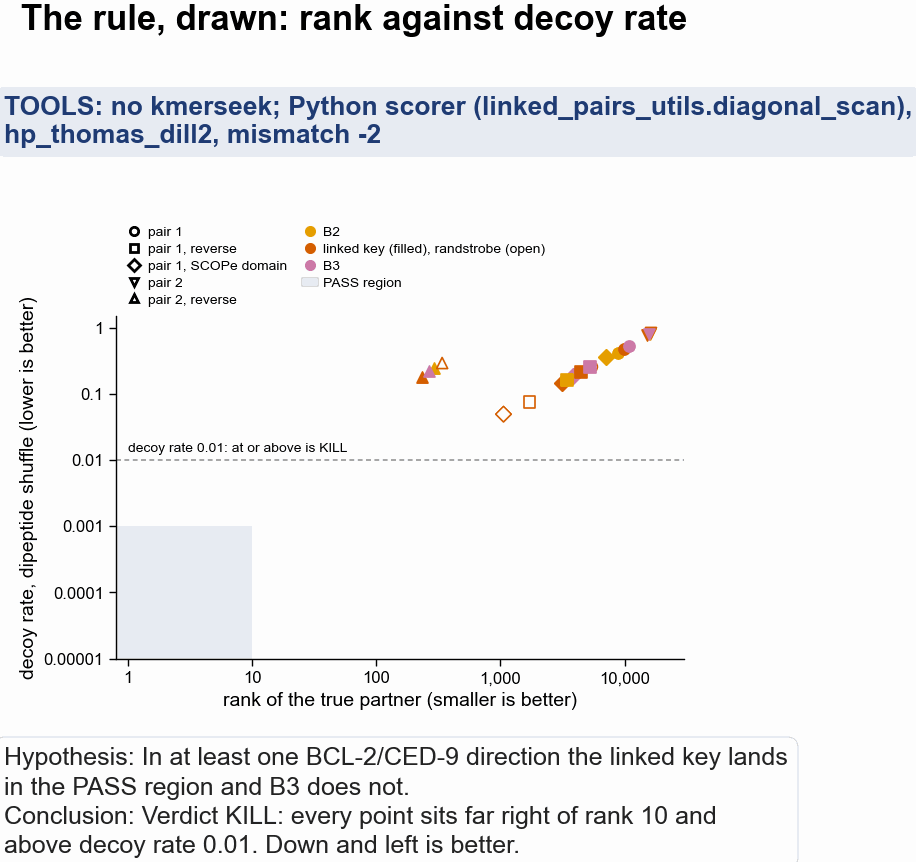

In [14]:
def get(pair, score, col):
    return RES.filter((pl.col("pair") == pair) & (pl.col("score") == score))[col][0]


DIRS = ["pair 1", "pair 1, reverse"]
DEC = "decoy_rate_dipeptide"
rule_rows = []
for p in DIRS:
    rL, rB3, dL, dB3 = (
        get(p, "linked", "rank"),
        get(p, "B3", "rank"),
        get(p, "linked", DEC),
        get(p, "B3", DEC),
    )
    rule_rows.append(
        {
            "direction": p,
            "linked rank": rL,
            "B3 rank": rB3,
            "linked decoy rate": round(dL, 4),
            "B3 decoy rate": round(dB3, 4),
            "PASS here (linked <= 10 and <= 0.001, B3 not)": (rL <= 10 and dL <= 1e-3)
            and not (rB3 <= 10 and dB3 <= 1e-3),
            "KILL here (linked rank no better than B3, or decoy rate >= 0.01)": rL
            >= rB3
            or dL >= 0.01,
        }
    )
RULE = pl.DataFrame(rule_rows)
print(RULE)
if RULE["PASS here (linked <= 10 and <= 0.001, B3 not)"].any():
    VERDICT = "PASS"
elif RULE["KILL here (linked rank no better than B3, or decoy rate >= 0.01)"].all():
    VERDICT = "KILL"
else:
    VERDICT = "UNCLEAR"
alt_kill = all(r["linked rank"] >= r["B3 rank"] for r in rule_rows) or all(
    r["linked decoy rate"] >= 0.01 for r in rule_rows
)
print(
    f"Verdict: {VERDICT}. (Reading the KILL line as 'both directions rank no better than B3, or both decoy rates >= 0.01' "
    f"gives {'KILL' if alt_kill else 'not KILL'}.)"
)

p1 = RES.filter(pl.col("pair") == "pair 1")
p66 = RES.filter((pl.col("pair") == "pair 2") & (pl.col("score") == "linked")).row(
    0, named=True
)
preds = [
    (
        "P1",
        all(p1["rank"] > 10),
        "BCL-2 ranks "
        + ", ".join(f"{s} {r:,}" for s, r in zip(p1["score"], p1["rank"])),
    ),
    (
        "P2",
        get("pair 1", "linked", "rank") >= get("pair 1", "B3", "rank"),
        f"linked {get('pair 1', 'linked', 'rank'):,}, B3 {get('pair 1', 'B3', 'rank'):,}",
    ),
    (
        "P3",
        get("pair 1", "linked", DEC) > 1e-3,
        f"decoy rate {get('pair 1', 'linked', DEC):.4f} (uniform {get('pair 1', 'linked', 'decoy_rate_uniform'):.4f})",
    ),
    (
        "P4",
        p66["rank"] > 0.01 * p66["n_real"] or p66[DEC] > 0.01,
        f"CD47 rank {p66['rank']:,} of {p66['n_real']:,} (top 1% = rank {0.01 * p66['n_real']:.0f} or better); decoy rate {p66[DEC]:.4f}",
    ),
]
pf_rows = RES.filter(
    pl.col("pair").str.starts_with("pair ")
    & pl.col("database").eq("Swiss-Prot")
    & (pl.col("score") == "linked")
)
if pf_rows.height == 4:
    n_low = int((pf_rows[DEC] <= 1e-3).sum())
    preds.append(
        (
            "P5",
            n_low <= 2,
            f"{n_low} of 4 at or below 0.001: "
            + ", ".join(f"{p} {v:.4f}" for p, v in zip(pf_rows["pair"], pf_rows[DEC])),
        )
    )
else:
    preds.append(("P5", None, "not tested yet: the Swiss-Prot scan has not run"))
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75, layout=None)
fig.subplots_adjust(left=0.16, right=0.97, top=0.72, bottom=0.14)
ax.axvspan(0.5, 10, ymin=0, ymax=1, color="none")
ax.fill_between(
    [0.8, 10],
    1e-5,
    1e-3,
    color=ku.COLOR["real"],
    alpha=0.25,
    lw=0,
    label="PASS region: rank 10 or better, decoy rate 0.001 or below",
)
ax.axhline(0.01, color=ku.COLOR["real"], lw=0.6, ls=(0, (3, 2)))
ax.text(1.0, 0.012, "decoy rate 0.01: at or above is KILL", fontsize=5, va="bottom")
mk = {
    "pair 1": "o",
    "pair 1, reverse": "s",
    "pair 1, SCOPe domain": "D",
    "pair 2": "v",
    "pair 2, reverse": "^",
}
col_ = {
    "B2": ku.COLOR["B2"],
    "linked": ku.COLOR["linked"],
    "randstrobe": ku.COLOR["linked"],
    "B3": ku.COLOR["B3"],
}
for (pair, score), g in RES.group_by(["pair", "score"], maintain_order=True):
    filled = score != "randstrobe"
    ax.scatter(
        g["rank"],
        g[DEC].clip(1e-5, None),
        marker=mk.get(pair, "P"),
        s=16,
        facecolors=col_[score] if filled else "none",
        edgecolors=col_[score],
        linewidths=0.6,
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.8, 3e4)
ax.set_ylim(1e-5, 1.5)
ax.set_xticks([1, 10, 100, 1000, 10_000], ["1", "10", "100", "1,000", "10,000"])
ax.set_yticks(
    [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1], ["0.00001", "0.0001", "0.001", "0.01", "0.1", "1"]
)
ax.minorticks_off()
ax.set_xlabel("rank of the true partner (smaller is better)")
ax.set_ylabel("decoy rate, dipeptide shuffle (lower is better)")
handles = [
    Line2D([], [], marker=m, ls="", color="black", markerfacecolor="white", label=p)
    for p, m in mk.items()
    if p in RES["pair"].to_list()
]
handles += [
    Line2D([], [], marker="o", ls="", color=col_[k], label=lab)
    for k, lab in [
        ("B2", "B2"),
        ("linked", "linked key (filled), randstrobe (open)"),
        ("B3", "B3"),
    ]
]
ax.legend(
    handles=handles + [Patch(color=ku.COLOR["real"], alpha=0.25, label="PASS region")],
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncol=2,
    frameon=False,
    fontsize=5,
)
hc.finish_figure(
    fig,
    FIG / "346_verdict_rank_vs_decoy_rate.png",
    tools=TOOL,
    hypothesis="In at least one BCL-2/CED-9 direction the linked key lands in the PASS region and B3 does not.",
    conclusion=f"Verdict {VERDICT}: every point sits far right of rank 10 and above decoy rate 0.01. Down and left is better.",
    title="The rule, drawn: rank against decoy rate",
    wrap=70,
    tight_layout=False,
)
PRED = pl.DataFrame(
    [
        {
            "prediction": a,
            "held": ("held" if b else "failed") if b is not None else "not tested yet",
            "number": c,
        }
        for a, b, c in preds
    ]
)
print(PRED)

### Not tested

Other alphabets; three or more anchors; other anchor lengths, windows and mismatch scores;
SCOPe pairs; FoldSeek or any structure search; kmerseek's own index and E-values for the
linked key (only kmerseek's existing exact-word seeds with chaining, section 3); proteomes
other than the four listed.

## Summary & Conclusions

### Background

[Notebook 294](294_linked_hp_word_pairs_kill_test_pfam_seed.ipynb) scored linked HP word
pairs (strobemers) on each pair's own alignment. This notebook asks whether the linked key
still finds a true partner when it has to beat every protein of a proteome and their
shuffled copies, on six pairs whose answer is known.

### Summary and Conclusions

* The linked HP key ranks BCL-2 at 9,952 of 19,732 human proteins when CED-9 is the query,
  with 48% of dipeptide-shuffled decoys scoring as high.
* The linked HP key ranks CED-9 at 4,493 of 19,792 *C. elegans* proteins when BCL-2 is the
  query, with a decoy rate of 21%.
* The linked key ranks the true partner better than B3 in both directions (9,952 vs 10,798;
  4,493 vs 5,244), but neither score comes near the rule's rank of 10 or decoy rate of 0.001.
* BCL-2's best key against the whole CED-9 sequence (score 37) has none of its 79 residue
  pairs on the structure alignment, whose own best linked key scores 32.
* Each human protein shares a median of 41,720 linked keys with CED-9 across all diagonals,
  against 3,896 that notebook 294 counted on one diagonal of two 131-residue proteins.
* P66 shares fewer exact 6-letter HP words with CD47 (2,771) than 74% of 1,000 human
  proteins of CD47's length do.
* The top 20 human proteins for CED-9 under the linked key are unrelated to BCL-2 and
  longer than average (median 754 against 427 residues); score and length correlate at 0.63.

### Analysis Details

The four scores of notebook 294 (B2, the chosen linked key, its randstrobe and B3) were
rewritten to run on every diagonal of two whole proteins (`linked_pairs_utils.diagonal_scan`).
Restricted to an alignment's cells the new scorer gives notebook 294's values (gates 1 and
2, and 30 random gapped alignments in the tests). The second anchor of a linked key may sit
on another diagonal, because the gap is not part of the key; the two segments may then not
overlap in either protein. Each protein of the human, *C. elegans* and *B. burgdorferi*
proteomes was scored as it is and as two decoys: a uniform residue shuffle and a
dipeptide-preserving shuffle. Of the 19,732 human proteins, 8 dipeptide shuffles failed and
were left out of the decoys (46 of 19,792 in *C. elegans*, none in *B. burgdorferi*).

The structure alignment of BCL-2 and CED-9 carries 23.6 bits in the HP alphabet under
notebook 245's model (κ = 0.463), and the best linked key with its extension carries 19.9
bits; E = 1 against one proteome needs 25.7. The task brief quoted 22.9 bits for the whole
alignment from notes; that number is not printed by notebook 245 and is not reproduced here.

CED-9's SCOPe domain d1ohua_ (CED-9 71–242 as crystallised, with C107S, C135S and C164S)
ranks BCL-2 higher than full-length CED-9 does: 3,162 under the linked key and 1,058 under
the randstrobe, still with decoy rates of 15% and 5%. MCL1 is the best-scoring BCL-2 family
member for CED-9 (linked score 44); BCL-2 scores 37.

### Supplementary Information

- Score tables: `~/data/linked-pairs/346_scan_*.parquet`, from `scripts/346_database_scan.py`
  (seeds 343_001 and 343_002 fix the decoys; the notebook was first numbered 343).
- Inputs and their sources: `tables/346_inputs.tsv`, `tables/346_databases.tsv`,
  `tables/346_known_pairs.tsv`, `tables/346_pfam_pairs.tsv`, `tables/346_sequences.fasta`.
- Results: `tables/346_ranks_and_decoy_rates.tsv`.
- Waiting on Sherlock: `scripts/346_swissprot_scan.sbatch` (pairs 3 to 6; about 46
  core-hours, 4.5 hours on the laptop) and `scripts/346_kmerseek_ced9_human.sbatch`.
- The SCOPe rescue numbers and the phmmer and jackhmmer E-values in the task brief come from
  notes whose scripts are not in this repository; they are kept in `tables/346_inputs.tsv`
  with kind "from notes, not reproduced here" and not used in any result.


## References

Hengartner, M. O., and H. R. Horvitz. "*C. elegans* Cell Survival Gene *ced-9* Encodes a
Functional Homolog of the Mammalian Proto-Oncogene *bcl-2*." *Cell* 76, no. 4 (1994):
665–76. https://doi.org/10.1016/0092-8674(94)90506-1

Sahlin, K. "Effective Sequence Similarity Detection with Strobemers." *Genome Research* 31,
no. 11 (2021): 2080–94. https://doi.org/10.1101/gr.275648.121

Tal, M. C., P. S. Hansen, H. A. Ogasawara, et al. "P66 Is a Bacterial Mimic of CD47 That
Binds the Anti-Phagocytic Receptor SIRPα and Facilitates Macrophage Evasion by *Borrelia
burgdorferi*." *bioRxiv* (2024), preprint. https://doi.org/10.1101/2024.04.29.591704

**Note:** Tal et al. align P66 (UniProt H7C7N8) with human CD47 in Clustal Omega and report
no region of significant sequence similarity; their P66 residues 181–187 hold D184 and D186,
needed for binding.